⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy...

METRICS (Keltner RSI Strategy)
     Final Equity: 20626.7236
     Total Return: 1.0627
    CAGR (approx): 0.3800
     Max Drawdown: -0.0783
           Sharpe: 2.5553
           Trades: 242
          Winrate: 0.5413
    Avg PnL/Trade: 43.3520
    Profit Factor: 1.7174


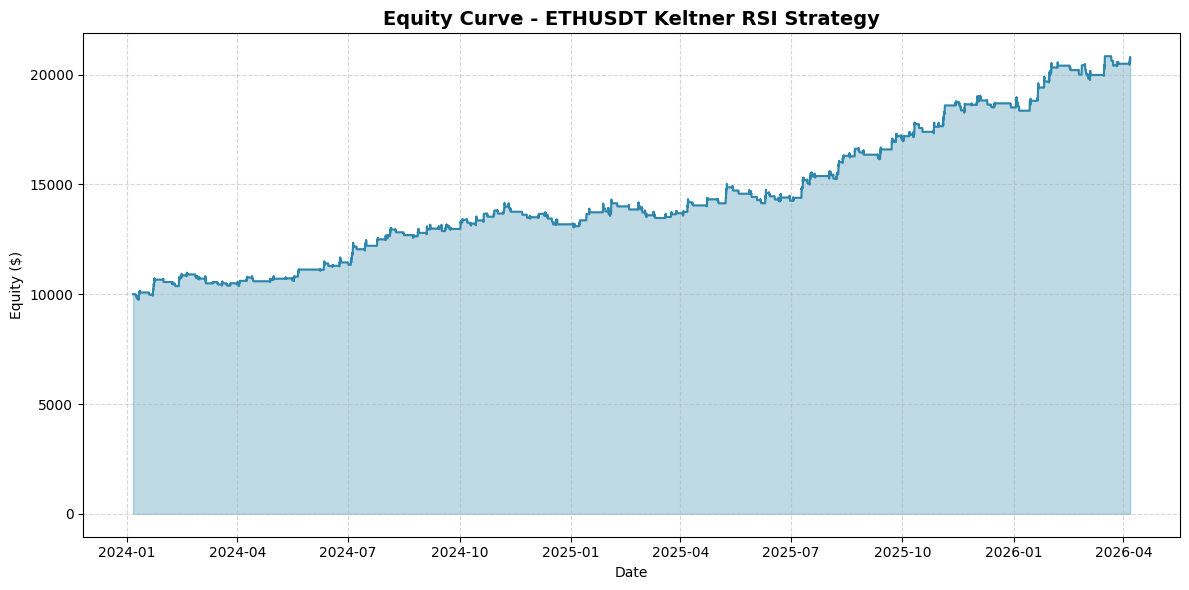


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2024-01-08 06:00:00  SHORT  2178.953135  2209.640279 -100.000000    Stop Loss   9900.000000
1 2024-01-09 00:00:00   LONG  2335.980000  2294.262617  -99.000000    Stop Loss   9801.000000
2 2024-01-10 21:00:00   LONG  2395.523862  2517.961424  195.828339  Take Profit   9996.828339
3 2024-01-11 15:00:00   LONG  2547.590000  2613.190000   81.970383    Time Exit  10078.798722
4 2024-01-19 09:00:00  SHORT  2439.500000  2478.667578 -100.787987    Stop Loss   9978.010735
5 2024-01-22 10:00:00  SHORT  2426.938557  2375.733320  237.290612  Take Profit  10215.301348
6 2024-01-22 19:00:00  SHORT  2378.078485  2314.262274  217.930241  Take Profit  10433.231588
7 2024-01-23 09:00:00  SHORT  2328.182940  2242.119715  206.422236  Take Profit  10639.653824
8 2024-01-24 03:00:00  SHORT  2223.350000  2213.450000   22.500548    Time Exit  10662.154373
9 2024-01-30 23:00:00   LONG  2

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)
    
    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])
    
    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])
    
    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.sl_coef = 2.0  # SL = 2 * ATR(20)
        self.tp_coef = 4.5  # TP = 4.5 * ATR(30)
        self.price_entry_mult = 2.4  # Entry buffer
        self.exit_after_bars = 16
        self.trailing_stop = 80  # pips/ticks
        self.trailing_activation = 90  # pips/ticks
        self.pending_expiration = 9
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=3 để lấy data
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Lấy data với shift đúng
                open_current = current_bar['Open']
                
                # KC Upper/Lower shift=1
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                
                # RSI momentum check: RSI[shift=2] vs RSI[shift=1]
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']
                
                # LONG SIGNAL
                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and  # RSI rising
                    open_current > kc_126_upper_prev
                )
                
                # SHORT SIGNAL
                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and  # RSI falling
                    open_current < kc_126_lower_prev
                )
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (Keltner RSI Strategy)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    
    plt.title(f"Equity Curve - {symbol} Keltner RSI Strategy", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "06/4/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Đang chạy Backtest Keltner RSI Strategy...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $15500.72
     Total Return: 55.01%
    CAGR (approx): 23.79%
     Max Drawdown: -8.19%
           Sharpe: 1.7071
           Trades: 222
          Winrate: 52.70%
    Avg PnL/Trade: $31.19
    Profit Factor: 1.58
       Total Fees: $2846.66
    Fee % of Init: 28.47%


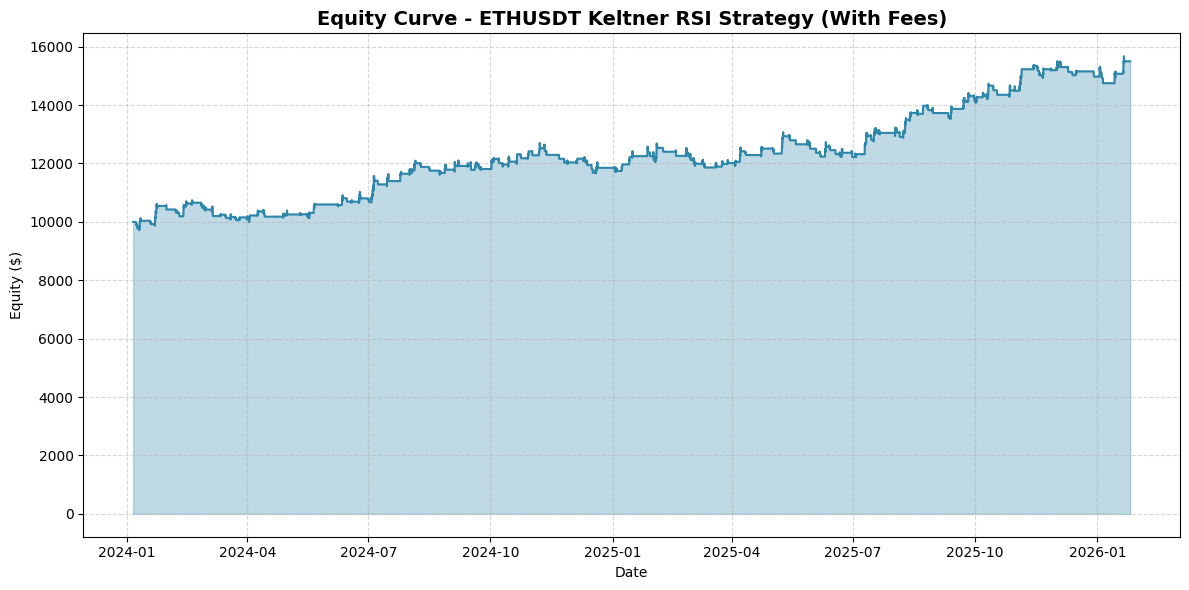


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit     Net PnL        Fee       Reason
0 2024-01-08 06:00:00  SHORT  2178.953135  2209.640279 -107.200541   7.200541    Stop Loss
1 2024-01-09 00:00:00   LONG  2335.980000  2294.262617 -104.293665   5.436676    Stop Loss
2 2024-01-10 21:00:00   LONG  2395.523862  2517.961424  191.309288   4.016936  Take Profit
3 2024-01-11 15:00:00   LONG  2547.590000  2613.190000   78.441559   3.254375    Time Exit
4 2024-01-19 09:00:00  SHORT  2439.500000  2478.667578 -106.739073   6.352810    Stop Loss
5 2024-01-22 10:00:00  SHORT  2426.938557  2375.733320  225.093426  10.951616  Take Profit
6 2024-01-22 19:00:00  SHORT  2378.078485  2314.262274  208.469466   7.844516  Take Profit
7 2024-01-23 09:00:00  SHORT  2328.182940  2242.119715  199.247005   5.329632  Take Profit
8 2024-01-24 03:00:00  SHORT  2223.350000  2213.450000   17.295823   4.980575    Time Exit
9 2024-01-30 23:00:00   LONG  2370.300000  2337.446358 -112.9

In [17]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)
    
    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])
    
    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])
    
    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.001):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Fee parameters
        self.fee_rate = fee_rate  # 0.1% = 0.001
        self.total_fees = 0
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.sl_coef = 2.0  # SL = 2 * ATR(20)
        self.tp_coef = 4.5  # TP = 4.5 * ATR(30)
        self.price_entry_mult = 2.4  # Entry buffer
        self.exit_after_bars = 16
        self.trailing_stop = 90  # pips/ticks
        self.trailing_activation = 90  # pips/ticks
        self.pending_expiration = 9
        
    def calculate_fee(self, price, quantity):
        """Tính phí giao dịch"""
        return price * quantity * self.fee_rate
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=3 để lấy data
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Lấy data với shift đúng
                open_current = current_bar['Open']
                
                # KC Upper/Lower shift=1
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                
                # RSI momentum check: RSI[shift=2] vs RSI[shift=1]
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']
                
                # LONG SIGNAL
                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and  # RSI rising
                    open_current > kc_126_upper_prev
                )
                
                # SHORT SIGNAL
                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and  # RSI falling
                    open_current < kc_126_lower_prev
                )
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
        
        # Tính và trừ phí mở lệnh
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees += entry_fee
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        # Tính phí đóng lệnh
        exit_fee = self.calculate_fee(price, self.qty)
        self.total_fees += exit_fee
        
        # PnL thực tế sau phí
        net_pnl = pnl - exit_fee
        self.balance += net_pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': net_pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees': total_fees,
        'Fee %': (total_fees / initial_balance) * 100,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (Keltner RSI Strategy)")
    print("="*60)
    print(f"     Final Equity: ${metrics['Final Equity']:.2f}")
    print(f"     Total Return: {metrics['Total Return']*100:.2f}%")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']*100:.2f}%")
    print(f"     Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']*100:.2f}%")
    print(f"    Avg PnL/Trade: ${metrics['Avg PnL/Trade']:.2f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.2f}")
    print(f"       Total Fees: ${metrics['Total Fees']:.2f}")
    print(f"    Fee % of Init: {metrics['Fee %']:.2f}%")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    
    plt.title(f"Equity Curve - {symbol} Keltner RSI Strategy (With Fees)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/1/2026"
    
    # Thiết lập phí giao dịch (0.1% cho maker/taker)
    fee_rate = 0.001  # 0.1%

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print(f"🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: {fee_rate*100}%)...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=10000, fee_rate=fee_rate)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df[['Exit Time', 'Type', 'Entry', 'Exit', 'Net PnL', 'Fee', 'Reason']].head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")


🔍 Đang xử lý: OSMOUSDT
⏳ Đang tải dữ liệu OSMOUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $17423.53
     Total Return: 74.24%
    CAGR (approx): 31.05%
     Max Drawdown: -6.36%
           Sharpe: 2.2376
           Trades: 212
          Winrate: 53.30%
    Avg PnL/Trade: $40.74
    Profit Factor: 1.63
       Total Fees: $2428.01
    Fee % of Init: 24.28%


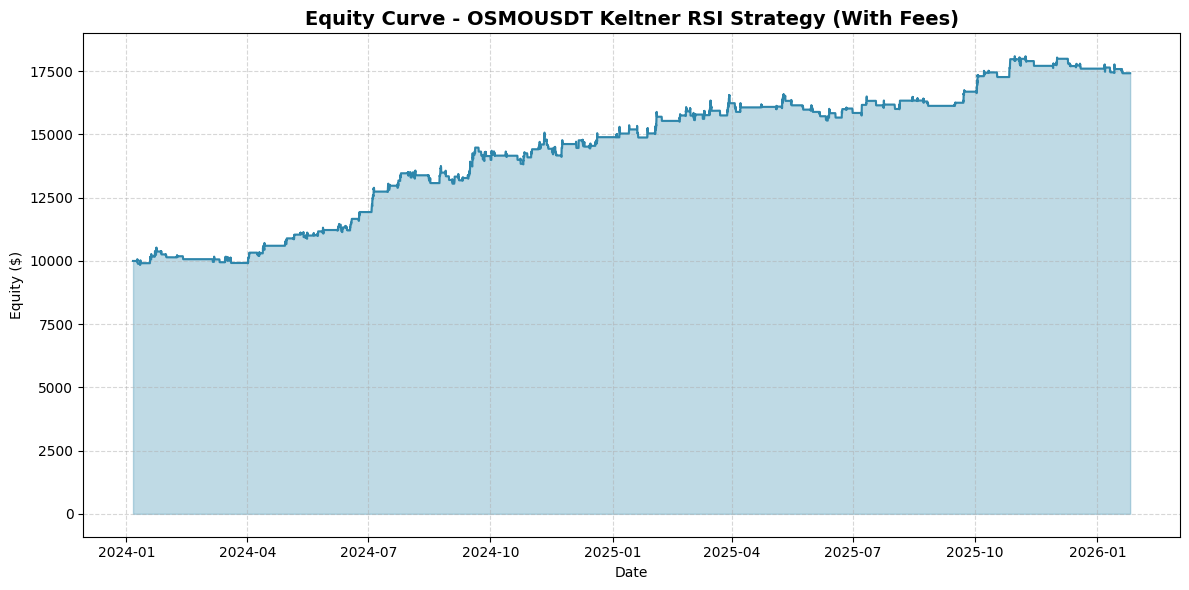


📊 Sample Trades (first 5):
            Exit Time   Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-01-09 09:00:00   LONG  1.873090  1.819264 -103.379926  3.379926    Stop Loss
1 2024-01-11 16:00:00   LONG  1.869537  1.885900   22.731986  2.961286    Time Exit
2 2024-01-18 19:00:00  SHORT  1.686011  1.624225  226.659400  6.119288  Take Profit
3 2024-01-19 17:00:00  SHORT  1.615297  1.598300   45.328861  4.704766    Time Exit
4 2024-01-22 10:00:00  SHORT  1.537206  1.478351  226.120921  5.826199  Take Profit

📊 Exit Reasons Distribution:
Reason
Stop Loss      85
Time Exit      70
Take Profit    57
Name: count, dtype: int64

🔍 Đang xử lý: PEPEUSDT
⏳ Đang tải dữ liệu PEPEUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $17297.05
     Total Return: 72.97%
    CAGR (approx): 30.58%
     Max Drawdown: -6.70%
           Sharpe: 2.2519
           Trades: 18

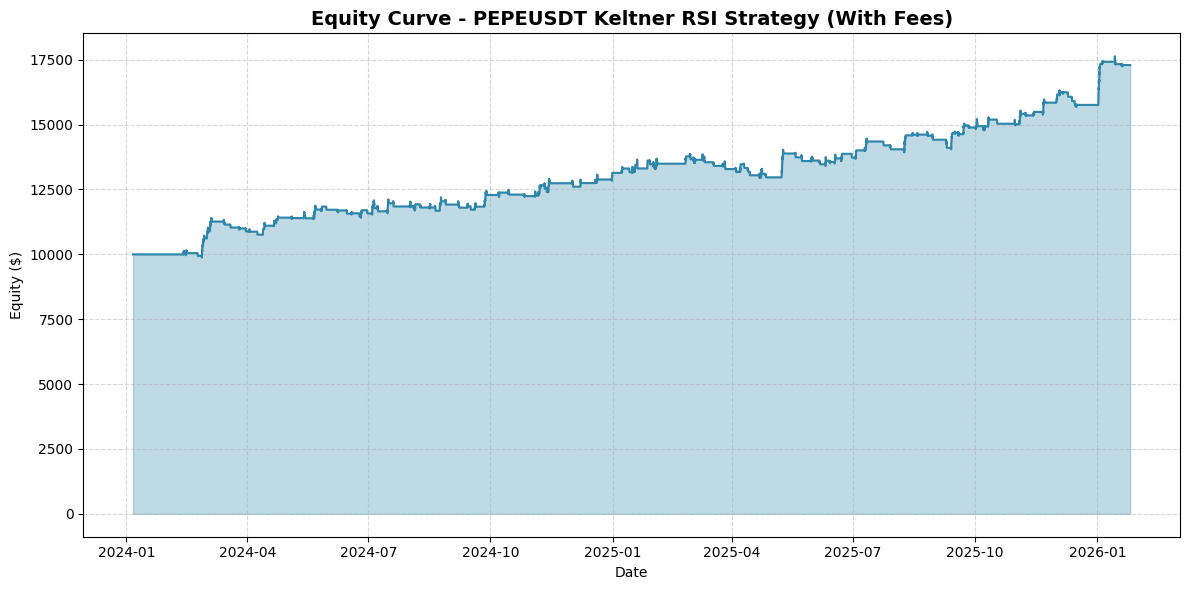


📊 Sample Trades (first 5):
            Exit Time  Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-02-13 12:00:00  LONG  0.000001  0.000001   38.922609  2.587549    Time Exit
1 2024-02-15 07:00:00  LONG  0.000001  0.000001   14.284535  2.003418    Time Exit
2 2024-02-23 14:00:00  LONG  0.000001  0.000001 -101.943112  1.456372    Stop Loss
3 2024-02-26 21:00:00  LONG  0.000002  0.000002  204.535680  1.857913  Take Profit
4 2024-02-27 03:00:00  LONG  0.000002  0.000002  193.405472  1.462144  Take Profit

📊 Exit Reasons Distribution:
Reason
Time Exit      66
Stop Loss      66
Take Profit    52
Name: count, dtype: int64

🔍 Đang xử lý: METISUSDT
⏳ Đang tải dữ liệu METISUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $15585.02
     Total Return: 55.85%
    CAGR (approx): 26.96%
     Max Drawdown: -7.87%
           Sharpe: 1.9491
           Trades: 184
  

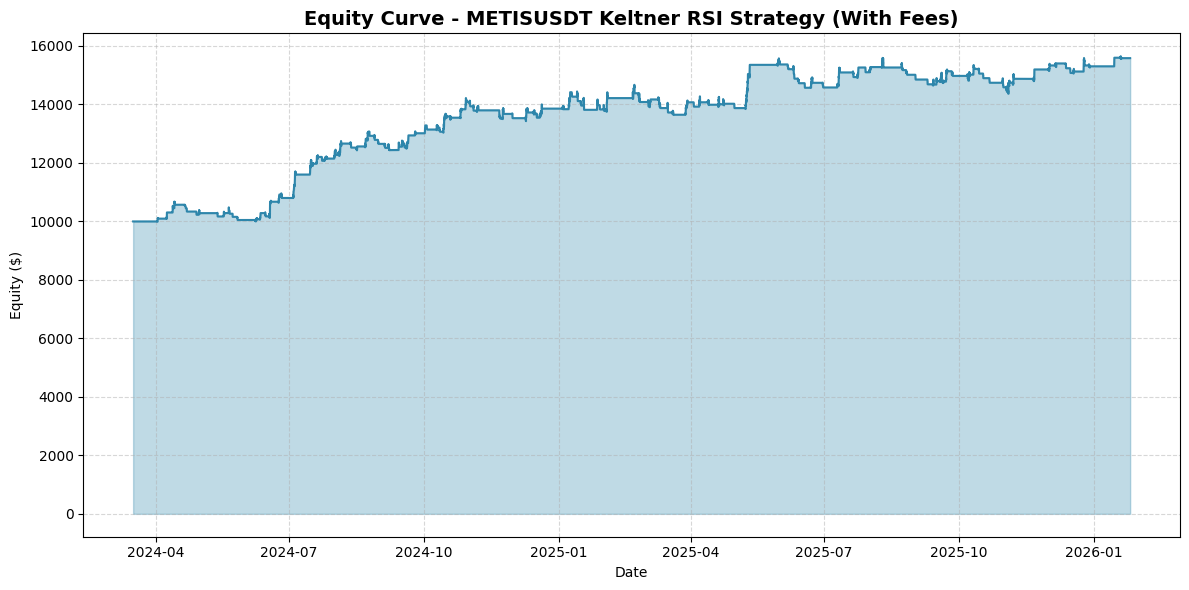


📊 Sample Trades (first 5):
            Exit Time   Type      Entry       Exit     Net PnL       Fee       Reason
0 2024-04-02 21:00:00  SHORT  92.040000  88.530000   99.140219  2.565238    Time Exit
1 2024-04-08 17:00:00   LONG  93.990000  98.399095  215.615945  4.921807  Take Profit
2 2024-04-12 17:00:00  SHORT  81.630000  76.054419  230.313696  3.185069  Take Profit
3 2024-04-13 11:00:00  SHORT  63.780000  68.010000  -77.614337  1.228138    Time Exit
4 2024-04-13 20:00:00  SHORT  61.971185  53.085571  225.784990  1.357021  Take Profit

📊 Exit Reasons Distribution:
Reason
Stop Loss      75
Time Exit      57
Take Profit    52
Name: count, dtype: int64

🔍 Đang xử lý: ETHUSDT
⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $15500.72
     Total Return: 55.01%
    CAGR (approx): 23.79%
     Max Drawdown: -8.19%
           Sharpe: 1.7071
           

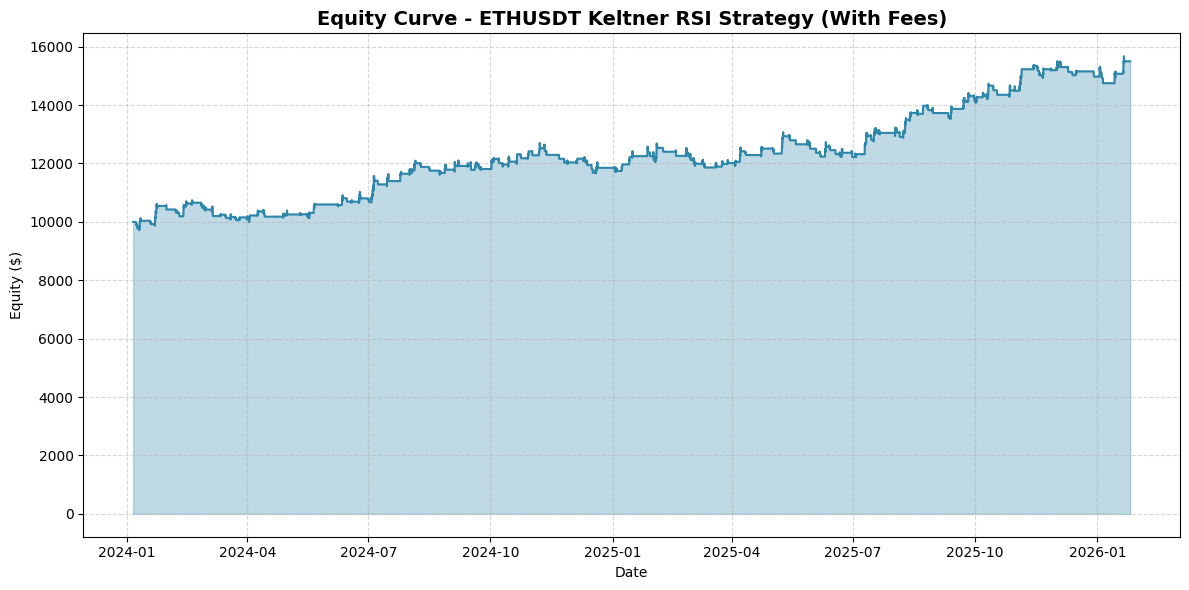


📊 Sample Trades (first 5):
            Exit Time   Type        Entry         Exit     Net PnL       Fee       Reason
0 2024-01-08 06:00:00  SHORT  2178.953135  2209.640279 -107.200541  7.200541    Stop Loss
1 2024-01-09 00:00:00   LONG  2335.980000  2294.262617 -104.293665  5.436676    Stop Loss
2 2024-01-10 21:00:00   LONG  2395.523862  2517.961424  191.309288  4.016936  Take Profit
3 2024-01-11 15:00:00   LONG  2547.590000  2613.190000   78.441559  3.254375    Time Exit
4 2024-01-19 09:00:00  SHORT  2439.500000  2478.667578 -106.739073  6.352810    Stop Loss

📊 Exit Reasons Distribution:
Reason
Time Exit        82
Stop Loss        81
Take Profit      51
Trailing Stop     8
Name: count, dtype: int64

🔍 Đang xử lý: FXSUSDT
⏳ Đang tải dữ liệu FXSUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13782.46
     Total Return: 37.82%
    CAGR (approx): 17.21%
     Max Draw

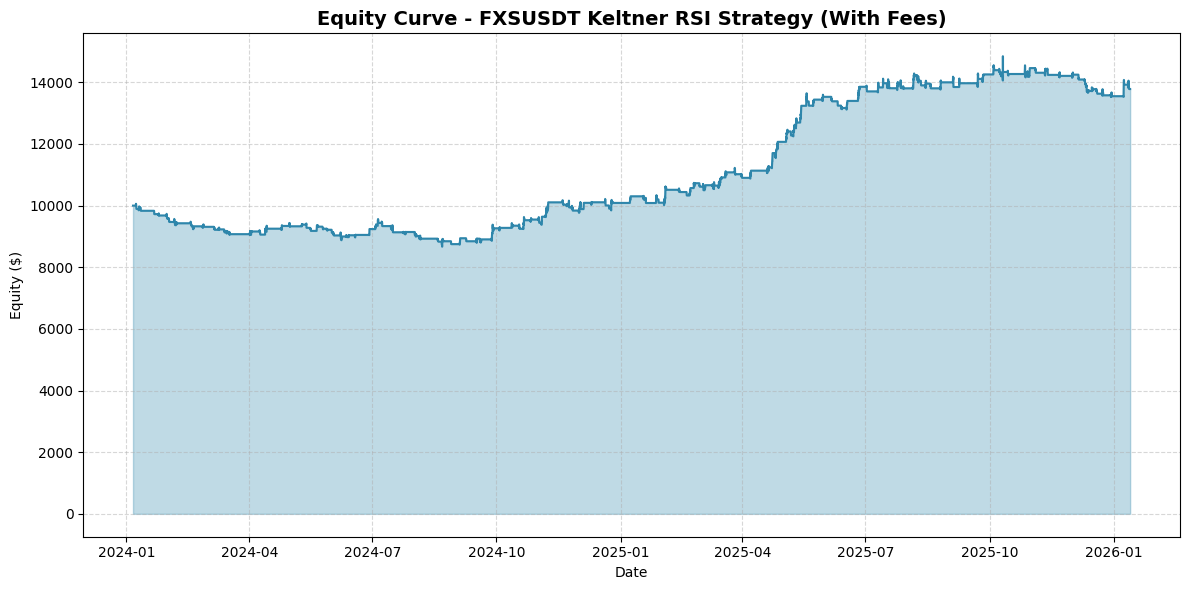


📊 Sample Trades (first 5):
            Exit Time   Type      Entry      Exit     Net PnL       Fee     Reason
0 2024-01-08 09:00:00  SHORT   7.508426  7.758255 -103.105418  3.105418  Stop Loss
1 2024-01-10 18:00:00   LONG   8.416000  8.594000   44.179692  2.241245  Time Exit
2 2024-01-11 16:00:00   LONG  10.027000  9.519952 -101.224224  1.865484  Stop Loss
3 2024-01-21 15:00:00   LONG   9.587017  9.388011 -102.965384  4.638535  Stop Loss
4 2024-01-25 03:00:00   LONG  10.038000  9.894000  -40.828760  2.624922  Time Exit

📊 Exit Reasons Distribution:
Reason
Time Exit      80
Stop Loss      74
Take Profit    44
Name: count, dtype: int64

🔍 Đang xử lý: FLOWUSDT
⏳ Đang tải dữ liệu FLOWUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13778.58
     Total Return: 37.79%
    CAGR (approx): 16.89%
     Max Drawdown: -6.33%
           Sharpe: 1.4363
           Trades: 166
    

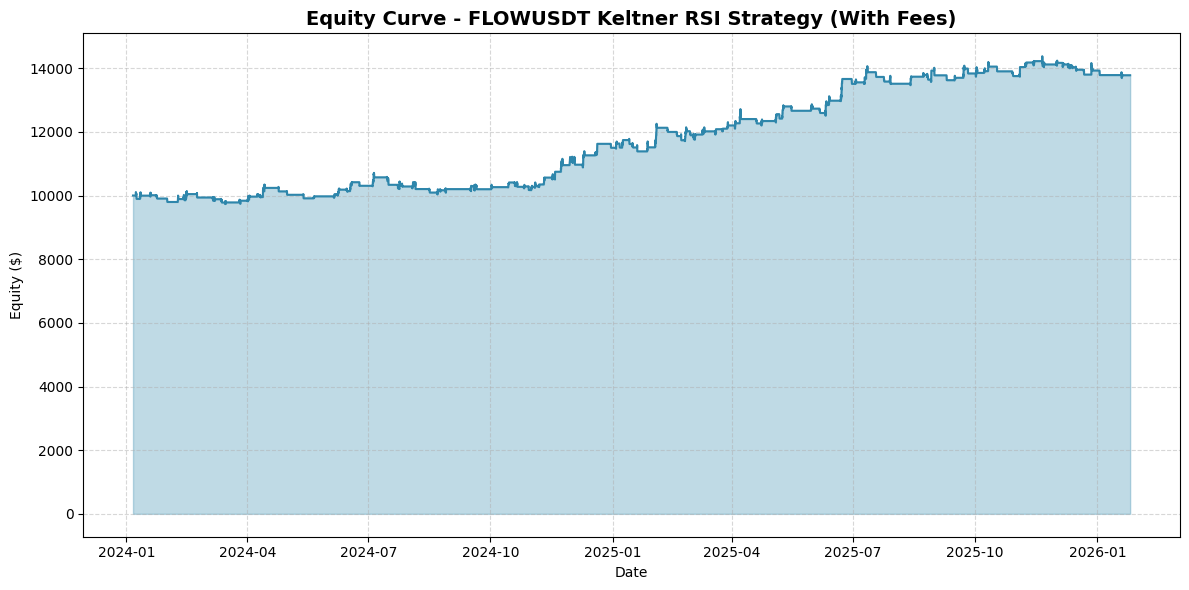


📊 Sample Trades (first 5):
            Exit Time   Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-01-08 13:00:00  SHORT  0.745488  0.772865 -102.823057  2.823057    Stop Loss
1 2024-01-11 13:00:00   LONG  0.819000  0.893390  209.970806  2.552321  Take Profit
2 2024-01-11 16:00:00   LONG  0.916992  0.878970 -103.356231  2.335382    Stop Loss
3 2024-01-19 11:00:00  SHORT  0.780539  0.776000   18.076974  3.727706    Time Exit
4 2024-01-23 23:00:00  SHORT  0.703000  0.731585 -102.668251  2.562054    Stop Loss

📊 Exit Reasons Distribution:
Reason
Time Exit      75
Stop Loss      61
Take Profit    30
Name: count, dtype: int64

🔍 Đang xử lý: ARUSDT
⏳ Đang tải dữ liệu ARUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13733.91
     Total Return: 37.34%
    CAGR (approx): 16.71%
     Max Drawdown: -10.68%
           Sharpe: 1.3475
           Trades: 182
 

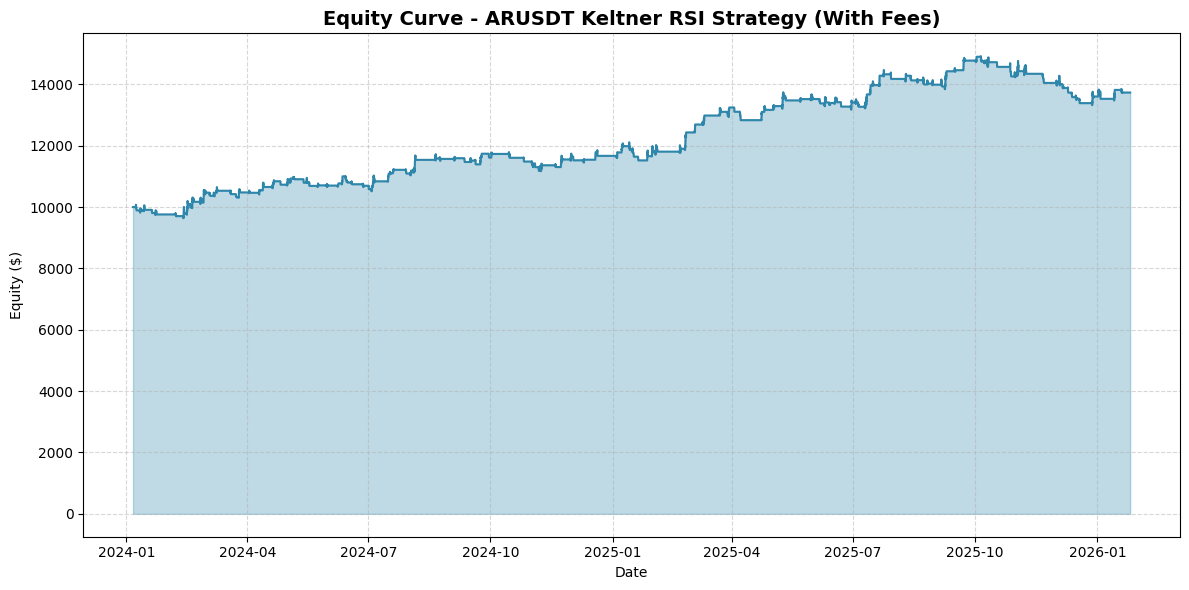


📊 Sample Trades (first 5):
            Exit Time   Type      Entry       Exit     Net PnL       Fee     Reason
0 2024-01-08 12:00:00  SHORT   7.896968   8.156109 -103.147363  3.147363  Stop Loss
1 2024-01-11 15:00:00   LONG   9.402000   9.350000  -14.153297  2.157022  Time Exit
2 2024-01-14 14:00:00   LONG  10.031619  10.179000   35.304464  2.619241  Time Exit
3 2024-01-20 05:00:00   LONG  10.689000  10.239700 -101.360631  2.258570  Stop Loss
4 2024-01-23 07:00:00  SHORT   8.768979   8.579000   61.181883  2.893494  Time Exit

📊 Exit Reasons Distribution:
Reason
Time Exit      87
Stop Loss      61
Take Profit    34
Name: count, dtype: int64

🔍 Đang xử lý: DOGEUSDT
⏳ Đang tải dữ liệu DOGEUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13464.64
     Total Return: 34.65%
    CAGR (approx): 15.59%
     Max Drawdown: -9.24%
           Sharpe: 1.1357
           Trades: 22

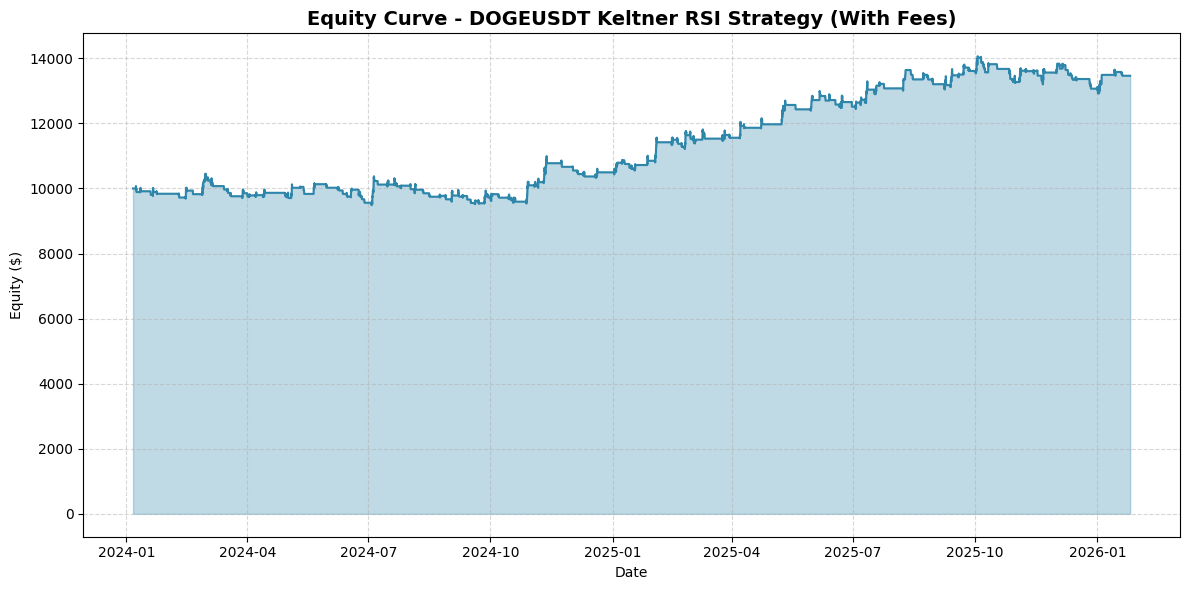


📊 Sample Trades (first 5):
            Exit Time   Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-01-08 12:00:00  SHORT  0.077270  0.078952 -104.695664  4.695664    Stop Loss
1 2024-01-11 16:00:00   LONG  0.083070  0.084000   27.363937  2.716987    Time Exit
2 2024-01-19 06:00:00  SHORT  0.076895  0.078276 -104.773538  5.619681    Stop Loss
3 2024-01-20 23:00:00   LONG  0.084690  0.088310  198.250654  4.957181  Take Profit
4 2024-01-21 03:00:00   LONG  0.089350  0.086845 -103.452751  3.466867    Stop Loss

📊 Exit Reasons Distribution:
Reason
Stop Loss      94
Time Exit      76
Take Profit    59
Name: count, dtype: int64

🔍 Đang xử lý: COTIUSDT
⏳ Đang tải dữ liệu COTIUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13298.44
     Total Return: 32.98%
    CAGR (approx): 14.89%
     Max Drawdown: -10.07%
           Sharpe: 1.1747
           Trades: 1

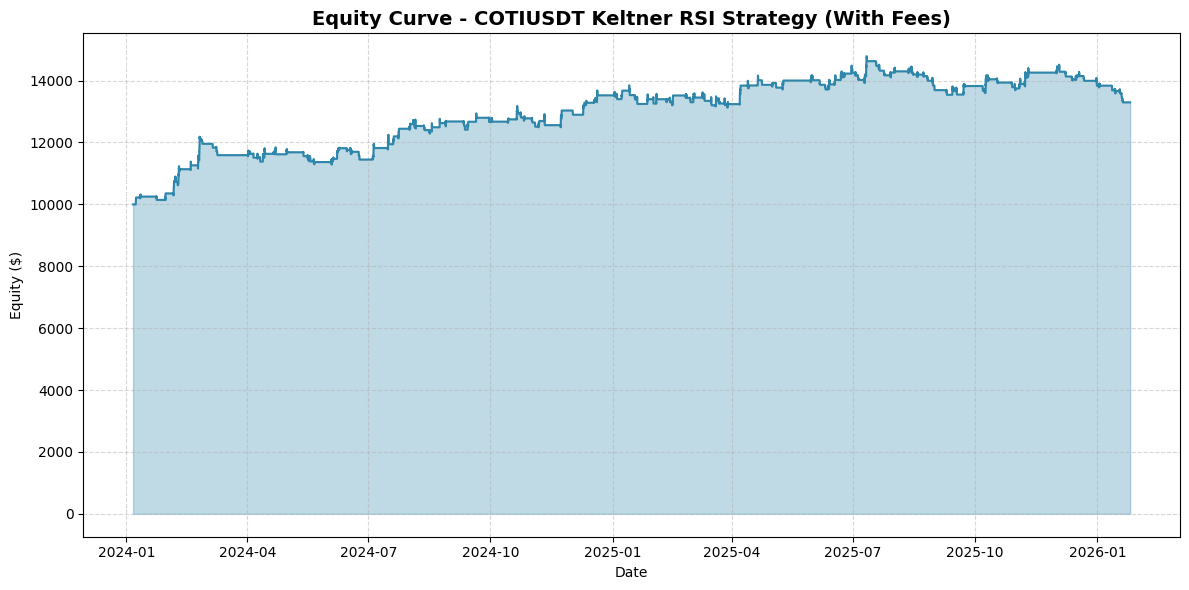


📊 Sample Trades (first 5):
            Exit Time   Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-01-08 03:00:00  SHORT  0.057315  0.053078  227.490873  2.885967  Take Profit
1 2024-01-11 16:00:00   LONG  0.063190  0.064090   30.757323  2.358193    Time Exit
2 2024-01-23 17:00:00  SHORT  0.050350  0.052279 -105.306728  2.778661    Stop Loss
3 2024-01-30 08:00:00   LONG  0.058630  0.061376  215.207881  4.919619  Take Profit
4 2024-02-05 14:00:00   LONG  0.058429  0.061277  210.815707  4.635618  Take Profit

📊 Exit Reasons Distribution:
Reason
Time Exit      76
Stop Loss      74
Take Profit    45
Name: count, dtype: int64

🔍 Đang xử lý: BONKUSDT
⏳ Đang tải dữ liệu BONKUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $13093.47
     Total Return: 30.93%
    CAGR (approx): 14.03%
     Max Drawdown: -15.87%
           Sharpe: 1.1163
           Trades: 1

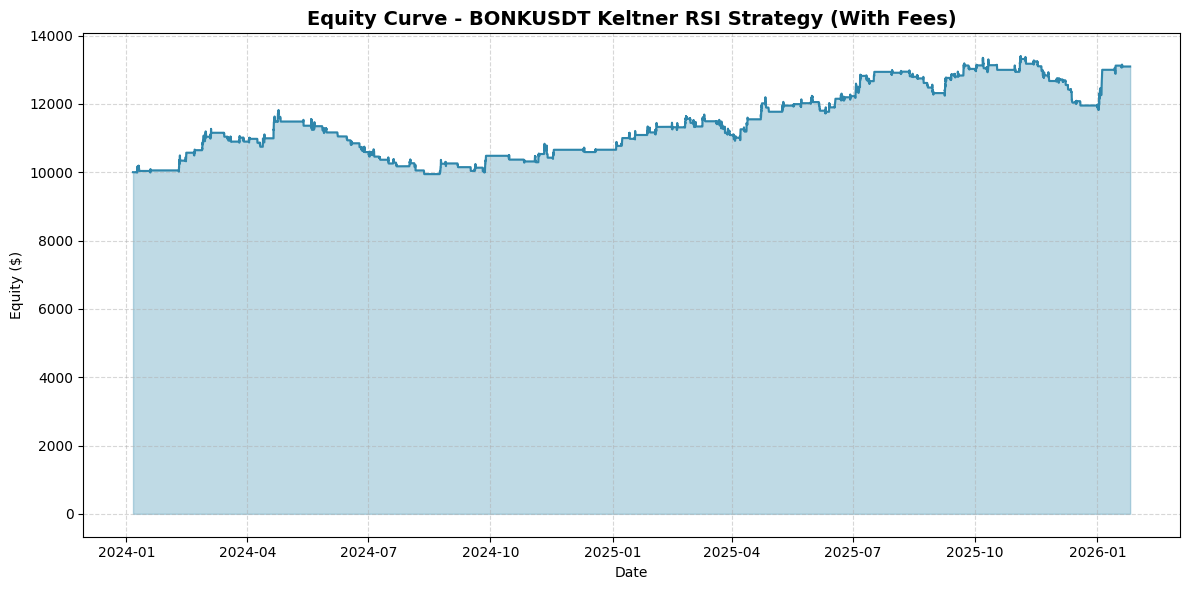


📊 Sample Trades (first 5):
            Exit Time   Type     Entry      Exit     Net PnL       Fee       Reason
0 2024-01-09 13:00:00   LONG  0.000012  0.000013  140.972292  1.435950    Time Exit
1 2024-01-10 12:00:00   LONG  0.000015  0.000014 -102.458713  1.061926    Stop Loss
2 2024-01-19 11:00:00  SHORT  0.000012  0.000012   18.739487  2.190788    Time Exit
3 2024-02-09 15:00:00   LONG  0.000011  0.000012  205.125030  3.527576  Take Profit
4 2024-02-10 03:00:00   LONG  0.000012  0.000013  195.676720  2.649971  Take Profit

📊 Exit Reasons Distribution:
Reason
Time Exit      80
Stop Loss      73
Take Profit    44
Name: count, dtype: int64

🔍 Đang xử lý: ORDIUSDT
⏳ Đang tải dữ liệu ORDIUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: 0.1%)...

METRICS (Keltner RSI Strategy)
     Final Equity: $12705.48
     Total Return: 27.05%
    CAGR (approx): 12.37%
     Max Drawdown: -11.82%
           Sharpe: 1.0843
           Trades: 1

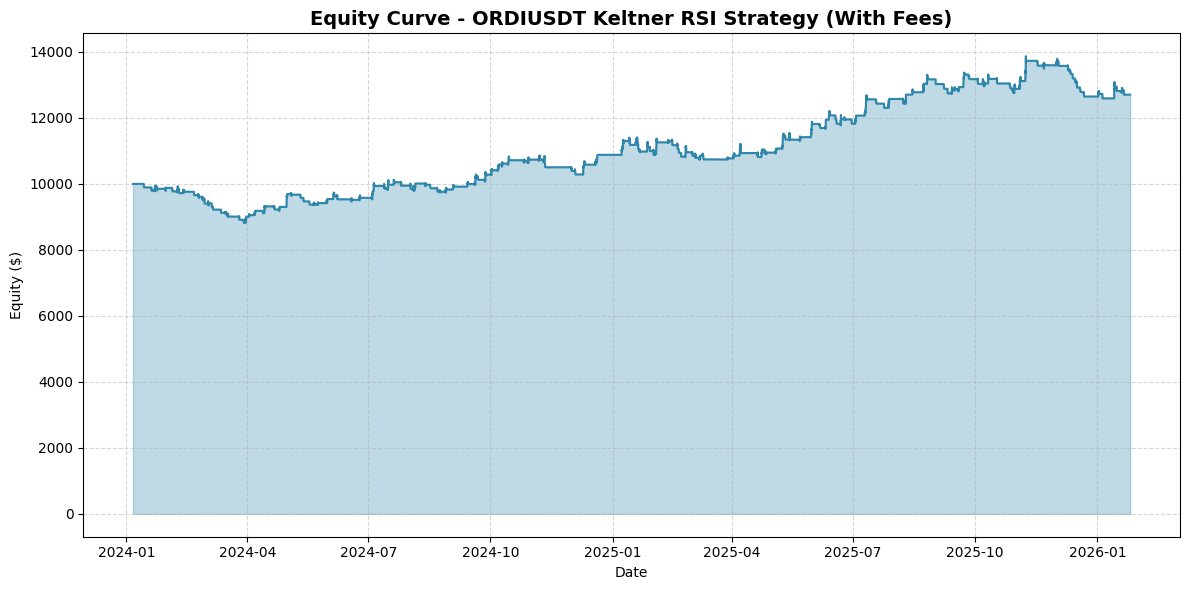


📊 Sample Trades (first 5):
            Exit Time   Type      Entry       Exit     Net PnL       Fee     Reason
0 2024-01-14 02:00:00   LONG  79.503613  76.286917 -102.371593  2.371593  Stop Loss
1 2024-01-19 23:00:00  SHORT  65.388486  68.251968 -101.310109  2.358541  Stop Loss
2 2024-01-22 20:00:00  SHORT  64.233235  63.459000   39.660074  3.540901  Time Exit
3 2024-01-24 02:00:00  SHORT  55.162000  54.303000   25.914558  1.748780  Time Exit
4 2024-01-30 18:00:00   LONG  62.225383  62.916000   30.758090  3.082960  Time Exit

📊 Exit Reasons Distribution:
Reason
Stop Loss      79
Time Exit      77
Take Profit    41
Name: count, dtype: int64

📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ COINS
   symbol final_equity total_return   cagr  max_dd sharpe  trades winrate profit_factor total_fees
 OSMOUSDT    $17423.53       74.24% 31.05%  -6.36%   2.24     212  53.30%          1.63   $2428.01
 PEPEUSDT    $17297.05       72.97% 30.58%  -6.70%   2.25     184  52.17%          1.81   $1213.66
METISUSDT    $15

In [25]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)
    
    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])
    
    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])
    
    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.001):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Fee parameters
        self.fee_rate = fee_rate  # 0.1% = 0.001
        self.total_fees = 0
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.sl_coef = 2.0  # SL = 2 * ATR(20)
        self.tp_coef = 4.5  # TP = 4.5 * ATR(30)
        self.price_entry_mult = 2.4  # Entry buffer
        self.exit_after_bars = 16
        self.trailing_stop = 90  # pips/ticks
        self.trailing_activation = 90  # pips/ticks
        self.pending_expiration = 9
        
    def calculate_fee(self, price, quantity):
        """Tính phí giao dịch"""
        return price * quantity * self.fee_rate
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=3 để lấy data
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Lấy data với shift đúng
                open_current = current_bar['Open']
                
                # KC Upper/Lower shift=1
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                
                # RSI momentum check: RSI[shift=2] vs RSI[shift=1]
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']
                
                # LONG SIGNAL
                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and  # RSI rising
                    open_current > kc_126_upper_prev
                )
                
                # SHORT SIGNAL
                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and  # RSI falling
                    open_current < kc_126_lower_prev
                )
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
        
        # Tính và trừ phí mở lệnh
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees += entry_fee
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        # Tính phí đóng lệnh
        exit_fee = self.calculate_fee(price, self.qty)
        self.total_fees += exit_fee
        
        # PnL thực tế sau phí
        net_pnl = pnl - exit_fee
        self.balance += net_pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': net_pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees': total_fees,
        'Fee %': (total_fees / initial_balance) * 100,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (Keltner RSI Strategy)")
    print("="*60)
    print(f"     Final Equity: ${metrics['Final Equity']:.2f}")
    print(f"     Total Return: {metrics['Total Return']*100:.2f}%")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']*100:.2f}%")
    print(f"     Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']*100:.2f}%")
    print(f"    Avg PnL/Trade: ${metrics['Avg PnL/Trade']:.2f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.2f}")
    print(f"       Total Fees: ${metrics['Total Fees']:.2f}")
    print(f"    Fee % of Init: {metrics['Fee %']:.2f}%")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    
    plt.title(f"Equity Curve - {symbol} Keltner RSI Strategy (With Fees)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. HÀM CHẠY BACKTEST CHO MỘT COIN ---
def run_backtest_for_symbol(symbol, interval, start_date, end_date, initial_balance, fee_rate):
    """Chạy backtest cho một coin"""
    print(f"\n{'='*70}")
    print(f"🔍 Đang xử lý: {symbol}")
    print(f"{'='*70}")
    
    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print(f"🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: {fee_rate*100}%)...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=initial_balance, fee_rate=fee_rate)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 5):")
            print(trades_df[['Exit Time', 'Type', 'Entry', 'Exit', 'Net PnL', 'Fee', 'Reason']].head(5).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
            
            # Trả về metrics để so sánh
            return {
                'symbol': symbol,
                'final_equity': metrics['Final Equity'],
                'total_return': metrics['Total Return'],
                'cagr': metrics['CAGR (approx)'],
                'max_dd': metrics['Max Drawdown'],
                'sharpe': metrics['Sharpe'],
                'trades': metrics['Trades'],
                'winrate': metrics['Winrate'],
                'profit_factor': metrics['Profit Factor'],
                'total_fees': metrics['Total Fees']
            }
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
            return None
    else:
        print("❌ Không đủ dữ liệu.")
        return None

# --- 6. MAIN EXECUTION ---
if __name__ == "__main__":
    # Cấu hình chung
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/1/2026"
    initial_balance = 10000
    fee_rate = 0.001  # 0.1%
    
    # # Danh sách các coin cần test
    # symbols = [
    #     "BTCUSDT",
    #     "ETHUSDT",
    #     "BNBUSDT",
    #     "SOLUSDT",
    #     "XRPUSDT",
    #     "ADAUSDT",
    #     "DOGEUSDT",
    #     "AVAXUSDT",
    #     "LINKUSDT",
    #     "MATICUSDT",
    #     "SHIBUSDT", "PEPEUSDT", "FLOKIUSDT", "BONKUSDT"
    # ]
    import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)
    
    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])
    
    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])
    
    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.001):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Fee parameters
        self.fee_rate = fee_rate  # 0.1% = 0.001
        self.total_fees = 0
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.sl_coef = 2.0  # SL = 2 * ATR(20)
        self.tp_coef = 4.5  # TP = 4.5 * ATR(30)
        self.price_entry_mult = 2.4  # Entry buffer
        self.exit_after_bars = 16
        self.trailing_stop = 90  # pips/ticks
        self.trailing_activation = 90  # pips/ticks
        self.pending_expiration = 9
        
    def calculate_fee(self, price, quantity):
        """Tính phí giao dịch"""
        return price * quantity * self.fee_rate
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        
                        # Update trailing SL
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            # Also update main SL
                            self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=3 để lấy data
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Lấy data với shift đúng
                open_current = current_bar['Open']
                
                # KC Upper/Lower shift=1
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                
                # RSI momentum check: RSI[shift=2] vs RSI[shift=1]
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']
                
                # LONG SIGNAL
                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and  # RSI rising
                    open_current > kc_126_upper_prev
                )
                
                # SHORT SIGNAL
                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and  # RSI falling
                    open_current < kc_126_lower_prev
                )
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        self.trailing_activated = False
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
        
        # Tính và trừ phí mở lệnh
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees += entry_fee
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        # Tính phí đóng lệnh
        exit_fee = self.calculate_fee(price, self.qty)
        self.total_fees += exit_fee
        
        # PnL thực tế sau phí
        net_pnl = pnl - exit_fee
        self.balance += net_pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': net_pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees': total_fees,
        'Fee %': (total_fees / initial_balance) * 100,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (Keltner RSI Strategy)")
    print("="*60)
    print(f"     Final Equity: ${metrics['Final Equity']:.2f}")
    print(f"     Total Return: {metrics['Total Return']*100:.2f}%")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']*100:.2f}%")
    print(f"     Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']*100:.2f}%")
    print(f"    Avg PnL/Trade: ${metrics['Avg PnL/Trade']:.2f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.2f}")
    print(f"       Total Fees: ${metrics['Total Fees']:.2f}")
    print(f"    Fee % of Init: {metrics['Fee %']:.2f}%")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    
    plt.title(f"Equity Curve - {symbol} Keltner RSI Strategy (With Fees)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. HÀM CHẠY BACKTEST CHO MỘT COIN ---
def run_backtest_for_symbol(symbol, interval, start_date, end_date, initial_balance, fee_rate):
    """Chạy backtest cho một coin"""
    print(f"\n{'='*70}")
    print(f"🔍 Đang xử lý: {symbol}")
    print(f"{'='*70}")
    
    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print(f"🚀 Đang chạy Backtest Keltner RSI Strategy (Fee: {fee_rate*100}%)...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=initial_balance, fee_rate=fee_rate)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 5):")
            print(trades_df[['Exit Time', 'Type', 'Entry', 'Exit', 'Net PnL', 'Fee', 'Reason']].head(5).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
            
            # Trả về metrics để so sánh
            return {
                'symbol': symbol,
                'final_equity': metrics['Final Equity'],
                'total_return': metrics['Total Return'],
                'cagr': metrics['CAGR (approx)'],
                'max_dd': metrics['Max Drawdown'],
                'sharpe': metrics['Sharpe'],
                'trades': metrics['Trades'],
                'winrate': metrics['Winrate'],
                'profit_factor': metrics['Profit Factor'],
                'total_fees': metrics['Total Fees']
            }
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
            return None
    else:
        print("❌ Không đủ dữ liệu.")
        return None

# --- 6. MAIN EXECUTION ---
if __name__ == "__main__":
    # Cấu hình chung
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/1/2026"
    initial_balance = 10000
    fee_rate = 0.001  # 0.1%
    
    # Danh sách các coin cần test
    symbols = [
        # Top Market Cap
    "OSMOUSDT",
    "PEPEUSDT",
    "METISUSDT",
    "ETHUSDT",
    "FXSUSDT",
    "FLOWUSDT",
    "ARUSDT",
    "DOGEUSDT",
    "COTIUSDT",
    "BONKUSDT",
    "ORDIUSDT",
    ]
    # Chạy backtest cho từng coin
    results = []
    for symbol in symbols:
        result = run_backtest_for_symbol(symbol, interval, start_date, end_date, initial_balance, fee_rate)
        if result:
            results.append(result)
        time.sleep(1)  # Nghỉ 1s giữa các coin để tránh rate limit
    
    # Tổng hợp kết quả
    if results:
        print("\n" + "="*100)
        print("📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ COINS")
        print("="*100)
        
        summary_df = pd.DataFrame(results)
        summary_df = summary_df.sort_values('total_return', ascending=False)
        
        # Format đẹp
        summary_df['total_return'] = summary_df['total_return'].apply(lambda x: f"{x*100:.2f}%")
        summary_df['cagr'] = summary_df['cagr'].apply(lambda x: f"{x*100:.2f}%")
        summary_df['max_dd'] = summary_df['max_dd'].apply(lambda x: f"{x*100:.2f}%")
        summary_df['winrate'] = summary_df['winrate'].apply(lambda x: f"{x*100:.2f}%")
        summary_df['sharpe'] = summary_df['sharpe'].apply(lambda x: f"{x:.2f}")
        summary_df['profit_factor'] = summary_df['profit_factor'].apply(lambda x: f"{x:.2f}")
        summary_df['final_equity'] = summary_df['final_equity'].apply(lambda x: f"${x:.2f}")
        summary_df['total_fees'] = summary_df['total_fees'].apply(lambda x: f"${x:.2f}")
        
        print(summary_df.to_string(index=False))
        print("="*100)
        
        # Tìm coin tốt nhất
        best_coin = results[0] if results else None
        if best_coin:
            print(f"\n🏆 COIN TỐT NHẤT: {best_coin['symbol']}")
            print(f"   Total Return: {best_coin['total_return']*100:.2f}%")
            print(f"   Sharpe Ratio: {best_coin['sharpe']:.2f}")
            print(f"   Profit Factor: {best_coin['profit_factor']:.2f}")
    else:
        print("\n⚠️ Không có kết quả nào từ backtest.")

In [26]:
summary_df[:10]

,symbol,final_equity,total_return,cagr,max_dd,sharpe,trades,winrate,profit_factor,total_fees
0,OSMOUSDT,$17423.53,74.24%,31.05%,-6.36%,2.24,212,53.30%,1.63,$2428.01
1,PEPEUSDT,$17297.05,72.97%,30.58%,-6.70%,2.25,184,52.17%,1.81,$1213.66
2,METISUSDT,$15585.02,55.85%,26.96%,-7.87%,1.95,184,47.28%,1.54,$1501.98
3,ETHUSDT,$15500.72,55.01%,23.79%,-8.19%,1.71,222,52.70%,1.58,$2846.66
4,FXSUSDT,$13782.46,37.82%,17.21%,-13.82%,1.26,198,47.47%,1.43,$1429.55
5,FLOWUSDT,$13778.58,37.79%,16.89%,-6.33%,1.44,166,51.81%,1.55,$1432.59
6,ARUSDT,$13733.91,37.34%,16.71%,-10.68%,1.35,182,51.65%,1.48,$1209.23
7,DOGEUSDT,$13464.64,34.65%,15.59%,-9.24%,1.14,229,45.85%,1.34,$1873.99
8,COTIUSDT,$13298.44,32.98%,14.89%,-10.07%,1.17,195,45.64%,1.35,$1434.67
9,BONKUSDT,$13093.47,30.93%,14.03%,-15.87%,1.12,197,46.19%,1.35,$1104.21


In [29]:
summary_df

,Symbol,Initial,Final Equity,Return %,Max DD %,Sharpe,Trades,Win Rate %,Profit Factor,Total Fees
0,OSMOUSDT,2500.0,2920.957239,16.838290,-6.227644,1.407559,88,51.136364,1.444228,164.205352
1,PEPEUSDT,2500.0,3254.741783,30.189671,-6.701335,2.134020,96,50.000000,1.798686,147.188202
2,METISUSDT,2500.0,2815.574397,12.622976,-7.866396,0.972760,94,43.617021,1.300768,145.558243
3,ETHUSDT,2500.0,3300.057866,32.002315,-6.542349,2.075387,115,51.304348,1.670448,324.460883


🎯 PORTFOLIO BACKTEST - KELTNER RSI STRATEGY
Total Capital: $10000
Number of Coins: 3
Capital per Coin: $3333.33
Symbols: OSMOUSDT, PEPEUSDT, ETHUSDT

🔍 Đang xử lý: OSMOUSDT
⏳ Đang tải dữ liệu OSMOUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest...

📊 Kết quả OSMOUSDT:
  Final Equity: $3894.61
  Total Return: 16.84%
  Max Drawdown: -6.23%
  Trades: 88
  Winrate: 51.14%

🔍 Đang xử lý: PEPEUSDT
⏳ Đang tải dữ liệu PEPEUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest...

📊 Kết quả PEPEUSDT:
  Final Equity: $4339.66
  Total Return: 30.19%
  Max Drawdown: -6.70%
  Trades: 96
  Winrate: 50.00%

🔍 Đang xử lý: ETHUSDT
⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest...

📊 Kết quả ETHUSDT:
  Final Equity: $4400.08
  Total Return: 32.00%
  Max Drawdown: -6.54%
  Trades: 115
  Winrate: 51.30%

📊 KẾT QUẢ PORTFOLIO

📈 Individual Coin Performance:
  Symbol     Initial  Final Equity 

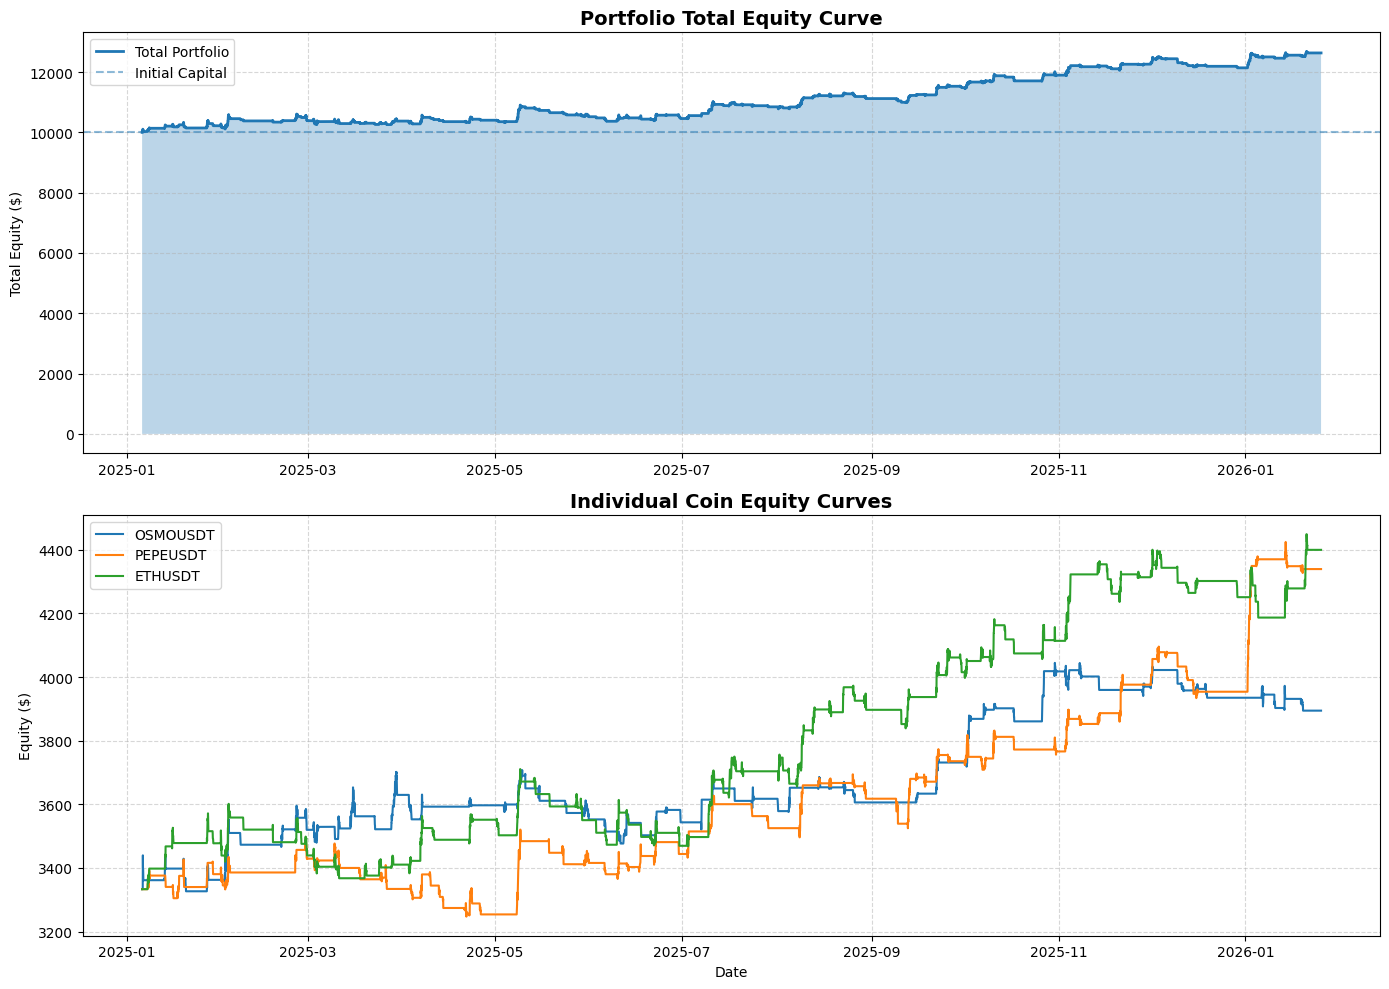

In [5]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1) HÀM TẢI DỮ LIỆU
# =========================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================
# 2) HÀM TÍNH CHỈ BÁO
# =========================
def calculate_indicators(df):
    data = df.copy()

    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2

    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)

    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)

    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])

    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])

    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()

    data.dropna(inplace=True)
    return data


# =========================
# 3) BACKTESTER
# =========================
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.001):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = []
        self.trades = []
        self.position = None
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None
        self.trailing_sl = None
        self.trailing_activated = False

        # Fee parameters
        self.fee_rate = fee_rate
        self.total_fees = 0

        # Strategy Parameters
        self.risk_pct = 0.01
        self.sl_coef = 2.0
        self.tp_coef = 4.5
        self.price_entry_mult = 2.4
        self.exit_after_bars = 16
        self.trailing_stop = 90
        self.trailing_activation = 90
        self.pending_expiration = 9

    def calculate_fee(self, price, quantity):
        return price * quantity * self.fee_rate

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # --- QUẢN LÝ VỊ THẾ ---
            if self.position is not None:
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                if self.position == 'LONG':
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue

                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = max(self.sl, self.trailing_sl)

                elif self.position == 'SHORT':
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue

                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = min(self.sl, self.trailing_sl)

            # --- XỬ LÝ PENDING ORDER ---
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']

                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position(
                            'LONG',
                            max(p_price, current_bar['Open']),
                            i,
                            self.pending_order['sl_dist'],
                            self.pending_order['tp_dist']
                        )
                        self.pending_order = None

                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position(
                            'SHORT',
                            min(p_price, current_bar['Open']),
                            i,
                            self.pending_order['sl_dist'],
                            self.pending_order['tp_dist']
                        )
                        self.pending_order = None

            # --- TẠO TÍN HIỆU (KHI KHÔNG CÓ POSITION & PENDING) ---
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(idx)
                    continue

                open_current = current_bar['Open']
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']

                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and
                    open_current > kc_126_upper_prev
                )

                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and
                    open_current < kc_126_lower_prev
                )

                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current

                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }

                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current

                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }

            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        current_price = self.df.loc[idx, 'Close']

        if self.position == 'LONG':
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized

        self.equity_curve.append({'time': idx, 'equity': mark_to_market})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx

        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist

        self.trailing_sl = None
        self.trailing_activated = False

        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0

        # Fee at entry
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees += entry_fee

    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        exit_fee = self.calculate_fee(price, self.qty)
        self.total_fees += exit_fee

        net_pnl = pnl - exit_fee
        self.balance += net_pnl

        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': net_pnl,
            'Reason': reason,
            'Balance': self.balance
        })

        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False


# =========================
# 4) METRICS TỪ EQUITY CURVE (CHO 1 COIN)
# =========================
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0

    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 0
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 and bars_per_year > 0 else 0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees': total_fees,
        'equity_df': eq_df
    }


# =========================
# 5) CHẠY BACKTEST 1 COIN
# =========================
def run_backtest_for_symbol(symbol, interval, start_date, end_date, initial_balance, fee_rate):
    print(f"\n{'='*70}")
    print(f"🔍 Đang xử lý: {symbol}")
    print(f"{'='*70}")

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)

        print(f"🚀 Đang chạy Backtest...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=initial_balance, fee_rate=fee_rate)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees)

            print(f"\n📊 Kết quả {symbol}:")
            print(f"  Final Equity: ${metrics['Final Equity']:.2f}")
            print(f"  Total Return: {metrics['Total Return']*100:.2f}%")
            print(f"  Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
            print(f"  Trades: {metrics['Trades']}")
            print(f"  Winrate: {metrics['Winrate']*100:.2f}%")

            return {
                'symbol': symbol,
                'backtester': bt,
                'metrics': metrics,
                'trades_df': trades_df
            }
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
            return None
    else:
        print("❌ Không đủ dữ liệu.")
        return None


# =========================
# 6) PORTFOLIO EQUITY (SUM)
# =========================
def calculate_portfolio_equity(results):
    """Tính tổng equity của portfolio từ tất cả các coin (cộng các equity riêng lẻ)"""
    if not results:
        return pd.DataFrame()

    all_equity_dfs = []
    for r in results:
        eq_df = pd.DataFrame(r['backtester'].equity_curve)
        eq_df.set_index('time', inplace=True)
        eq_df = eq_df.rename(columns={'equity': r['symbol']})
        all_equity_dfs.append(eq_df)

    portfolio_equity = all_equity_dfs[0]
    for eq_df in all_equity_dfs[1:]:
        portfolio_equity = portfolio_equity.join(eq_df, how='outer')

    portfolio_equity = portfolio_equity.sort_index()
    portfolio_equity = portfolio_equity.ffill()

    portfolio_equity['Total'] = portfolio_equity.sum(axis=1)
    return portfolio_equity


# =========================
# 7) PORTFOLIO METRICS (THIẾU TRONG CODE CŨ)
# =========================
def calculate_portfolio_metrics(portfolio_equity, all_trades_df, total_capital, total_fees):
    """
    Tính metrics portfolio dựa trên:
    - portfolio_equity['Total'] (equity curve tổng)
    - all_trades_df: concat trades của tất cả coin (Net PnL) để tính winrate/profit_factor
    """
    if portfolio_equity is None or portfolio_equity.empty:
        return None

    eq = portfolio_equity[['Total']].copy()
    eq = eq[~eq.index.duplicated(keep='last')].dropna()

    final_equity = float(eq['Total'].iloc[-1])
    total_return = (final_equity - total_capital) / total_capital

    days = (eq.index[-1] - eq.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / total_capital) ** (1 / years) - 1) if years > 0 else 0.0

    running_max = eq['Total'].cummax()
    drawdown = (eq['Total'] - running_max) / running_max
    max_dd = float(drawdown.min())

    eq['returns'] = eq['Total'].pct_change()
    mean_ret = eq['returns'].mean()
    std_ret = eq['returns'].std()

    bars_per_year = (len(eq) / years) if years > 0 else 0.0
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 and bars_per_year > 0 else 0.0

    total_trades = len(all_trades_df) if all_trades_df is not None else 0
    if total_trades > 0:
        win_trades = int((all_trades_df['Net PnL'] > 0).sum())
        win_rate = win_trades / total_trades
        gross_profit = all_trades_df.loc[all_trades_df['Net PnL'] > 0, 'Net PnL'].sum()
        gross_loss = abs(all_trades_df.loc[all_trades_df['Net PnL'] < 0, 'Net PnL'].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0
    else:
        win_rate = 0.0
        profit_factor = 0.0

    return {
        "final_equity": final_equity,
        "total_return": total_return,
        "cagr": cagr,
        "max_dd": max_dd,
        "sharpe": sharpe,
        "trades": total_trades,
        "winrate": win_rate,
        "profit_factor": profit_factor,
        "total_fees": float(total_fees),
        "equity_df": eq
    }


# =========================
# 8) VẼ PORTFOLIO
# =========================
def plot_portfolio_results(portfolio_equity, initial_total, symbols):
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))

    # Biểu đồ 1: Tổng Portfolio Equity
    ax1 = axes[0]
    ax1.plot(portfolio_equity.index, portfolio_equity['Total'], linewidth=2, label='Total Portfolio')
    ax1.fill_between(portfolio_equity.index, portfolio_equity['Total'], alpha=0.3)
    ax1.axhline(y=initial_total, linestyle='--', alpha=0.5, label='Initial Capital')
    ax1.set_title('Portfolio Total Equity Curve', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Total Equity ($)')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

    # Biểu đồ 2: Từng coin riêng lẻ
    ax2 = axes[1]
    for symbol in symbols:
        ax2.plot(portfolio_equity.index, portfolio_equity[symbol], linewidth=1.5, label=symbol)

    ax2.set_title('Individual Coin Equity Curves', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Equity ($)')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

    plt.tight_layout()
    plt.show()


# =========================
# 9) MAIN EXECUTION - PORTFOLIO MODE
# =========================
if __name__ == "__main__":
    # Cấu hình Portfolio
    portfolio_symbols = [
        "OSMOUSDT",
        "PEPEUSDT",
        # "METISUSDT",
        "ETHUSDT"
    ]

    # Cấu hình backtest
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "25/1/2026"
    total_capital = 10000

    # phí 0.0005 = 0.05% (nếu muốn 0.1% thì dùng 0.001)
    fee_rate = 0.001

    # Phân bổ vốn đều cho mỗi coin
    capital_per_coin = total_capital / len(portfolio_symbols)

    print("=" * 70)
    print("🎯 PORTFOLIO BACKTEST - KELTNER RSI STRATEGY")
    print("=" * 70)
    print(f"Total Capital: ${total_capital}")
    print(f"Number of Coins: {len(portfolio_symbols)}")
    print(f"Capital per Coin: ${capital_per_coin:.2f}")
    print(f"Symbols: {', '.join(portfolio_symbols)}")
    print("=" * 70)

    # Chạy backtest cho từng coin
    results = []
    for symbol in portfolio_symbols:
        result = run_backtest_for_symbol(symbol, interval, start_date, end_date, capital_per_coin, fee_rate)
        if result:
            results.append(result)
        time.sleep(1)

    # Tính toán và hiển thị kết quả portfolio
    if results:
        print("\n" + "=" * 70)
        print("📊 KẾT QUẢ PORTFOLIO")
        print("=" * 70)

        # Tổng hợp metrics từng coin
        summary_data = []
        for r in results:
            m = r['metrics']
            summary_data.append({
                'Symbol': r['symbol'],
                'Initial': capital_per_coin,
                'Final Equity': m['Final Equity'],
                'Return %': m['Total Return'] * 100,
                'CAGR %': m['CAGR (approx)'] * 100,
                'Max DD %': m['Max Drawdown'] * 100,
                'Sharpe': m['Sharpe'],
                'Trades': m['Trades'],
                'Win Rate %': m['Winrate'] * 100,
                'Profit Factor': m['Profit Factor'],
                'Total Fees': m['Total Fees']
            })

        summary_df = pd.DataFrame(summary_data)
        print("\n📈 Individual Coin Performance:")
        print(summary_df.to_string(index=False))

        # ---- PORTFOLIO EQUITY CURVE ----
        portfolio_equity = calculate_portfolio_equity(results)

        # ---- GOM TRADES TOÀN PORTFOLIO ----
        all_trades_df = pd.concat([r['trades_df'] for r in results], ignore_index=True)

        # ---- PORTFOLIO METRICS (FULL) ----
        total_fees = summary_df['Total Fees'].sum()
        portfolio_metrics = calculate_portfolio_metrics(
            portfolio_equity=portfolio_equity,
            all_trades_df=all_trades_df,
            total_capital=total_capital,
            total_fees=total_fees
        )

        # In theo đúng header bạn muốn: final_equity total_return cagr max_dd sharpe trades winrate profit_factor total_fees
        if portfolio_metrics:
            portfolio_metrics_df = pd.DataFrame([{
                "final_equity": portfolio_metrics["final_equity"],
                "total_return": portfolio_metrics["total_return"],
                "cagr": portfolio_metrics["cagr"],
                "max_dd": portfolio_metrics["max_dd"],
                "sharpe": portfolio_metrics["sharpe"],
                "trades": portfolio_metrics["trades"],
                "winrate": portfolio_metrics["winrate"],
                "profit_factor": portfolio_metrics["profit_factor"],
                "total_fees": portfolio_metrics["total_fees"],
            }])

            print("\n" + "=" * 70)
            print("💼 PORTFOLIO METRICS (Full)")
            print("=" * 70)
            print(portfolio_metrics_df.to_string(index=False))

            # In thêm dạng % cho dễ đọc
            print("\n📌 PORTFOLIO METRICS (Readable):")
            print(f"Initial Total Capital: ${total_capital:.2f}")
            print(f"Final Total Equity:   ${portfolio_metrics['final_equity']:.2f}")
            print(f"Total Return:         {portfolio_metrics['total_return']*100:.2f}%")
            print(f"CAGR (approx):        {portfolio_metrics['cagr']*100:.2f}%")
            print(f"Max Drawdown:         {portfolio_metrics['max_dd']*100:.2f}%")
            print(f"Sharpe:               {portfolio_metrics['sharpe']:.3f}")
            print(f"Total Trades:         {portfolio_metrics['trades']}")
            print(f"Winrate:              {portfolio_metrics['winrate']*100:.2f}%")
            print(f"Profit Factor:        {portfolio_metrics['profit_factor']:.3f}")
            print(f"Total Fees Paid:      ${portfolio_metrics['total_fees']:.2f}")
            print("=" * 70)

        # ---- VẼ BIỂU ĐỒ ----
        plot_portfolio_results(portfolio_equity, total_capital, portfolio_symbols)

    else:
        print("\n⚠️ Không có kết quả nào từ portfolio backtest.")


In [6]:
portfolio_metrics_df

,final_equity,total_return,cagr,max_dd,sharpe,trades,winrate,profit_factor,total_fees
0,12634.342519,0.263434,0.249091,-0.049364,2.563653,299,0.508361,1.636281,847.805915


🎯 PORTFOLIO BACKTEST - REBALANCING METHODS
Total Capital: $10000
Number of Coins: 2
Symbols: PEPEUSDT, ETHUSDT

🔍 Đang xử lý: PEPEUSDT
⏳ Đang tải dữ liệu PEPEUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest...

📊 Kết quả PEPEUSDT:
  Final Equity: $7881.53
  Total Return: 57.63%
  Max Drawdown: -9.93%
  Trades: 109
  Winrate: 49.54%

🔍 Đang xử lý: ETHUSDT
⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest...

📊 Kết quả ETHUSDT:
  Final Equity: $8166.55
  Total Return: 63.33%
  Max Drawdown: -9.74%
  Trades: 131
  Winrate: 51.15%

📊 COMPARISON OF REBALANCING METHODS

⚙️ Testing Equal Weight...

⚙️ Testing Inverse Volatility...

⚙️ Testing Risk Parity...

⚙️ Testing Momentum...

⚙️ Testing Sharpe Ratio...

            Method  Final Equity  Total Return %    CAGR %  Max DD %   Sharpe  Profit Factor
      Equal Weight  16150.401204       61.504012 49.555434 -7.693140 2.649659       1.735608
Inverse Volatil

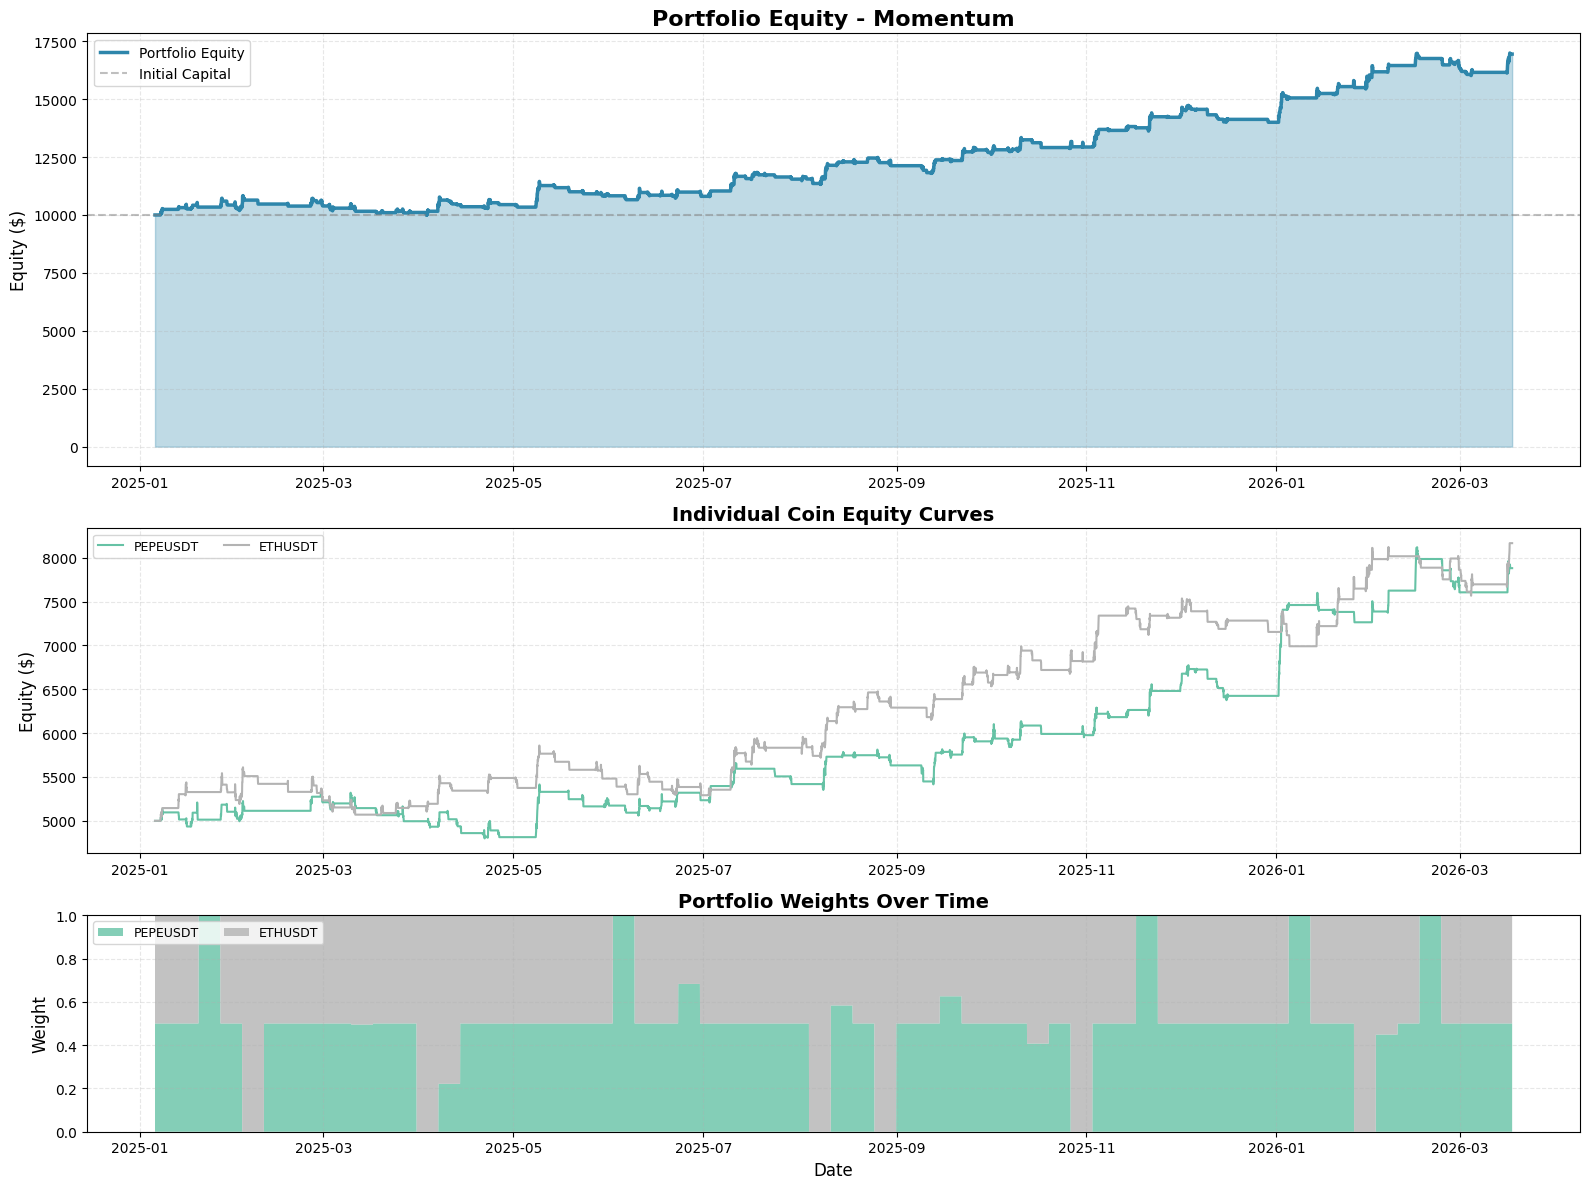

In [11]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1) HÀM TẢI DỮ LIỆU
# =========================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================
# 2) HÀM TÍNH CHỈ BÁO
# =========================
def calculate_indicators(df):
    data = df.copy()

    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2

    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)

    # RSI(50) on Median Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

    data['RSI_50'] = calc_rsi(data['Median_Price'], 50)

    # Keltner Channel (20, dev=2.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['ATR_20_KC'] = calc_atr(data['TR'], 20)
    data['KC_20_Upper'] = data['EMA_20'] + (2.5 * data['ATR_20_KC'])
    data['KC_20_Lower'] = data['EMA_20'] - (2.5 * data['ATR_20_KC'])

    # Keltner Channel (126, dev=2.5)
    data['EMA_126'] = data['Close'].ewm(span=126, adjust=False).mean()
    data['ATR_126'] = calc_atr(data['TR'], 126)
    data['KC_126_Upper'] = data['EMA_126'] + (2.5 * data['ATR_126'])
    data['KC_126_Lower'] = data['EMA_126'] - (2.5 * data['ATR_126'])

    # Highest/Lowest Close trong 14 nến
    data['Highest_Close_14'] = data['Close'].rolling(window=14).max()
    data['Lowest_Close_14'] = data['Close'].rolling(window=14).min()

    data.dropna(inplace=True)
    return data


# =========================
# 3) BACKTESTER
# =========================
class KeltnerRSIBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.001):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = []
        self.trades = []
        self.position = None
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None
        self.trailing_sl = None
        self.trailing_activated = False

        # Fee parameters
        self.fee_rate = fee_rate
        self.total_fees = 0

        # Strategy Parameters
        self.risk_pct = 0.015
        self.sl_coef = 2.0
        self.tp_coef = 4.5
        self.price_entry_mult = 2.4
        self.exit_after_bars = 16
        self.trailing_stop = 90
        self.trailing_activation = 90
        self.pending_expiration = 9

    def calculate_fee(self, price, quantity):
        return price * quantity * self.fee_rate

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # --- QUẢN LÝ VỊ THẾ ---
            if self.position is not None:
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                if self.position == 'LONG':
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue

                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit = current_bar['Close'] - self.entry_price
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        new_trailing_sl = current_bar['Close'] - self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = max(self.sl, self.trailing_sl)

                elif self.position == 'SHORT':
                    if self.trailing_activated and self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue

                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit = self.entry_price - current_bar['Close']
                    if profit >= self.trailing_activation:
                        if not self.trailing_activated:
                            self.trailing_activated = True
                        new_trailing_sl = current_bar['Close'] + self.trailing_stop
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = min(self.sl, self.trailing_sl)

            # --- XỬ LÝ PENDING ORDER ---
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']

                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position(
                            'LONG',
                            max(p_price, current_bar['Open']),
                            i,
                            self.pending_order['sl_dist'],
                            self.pending_order['tp_dist']
                        )
                        self.pending_order = None

                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position(
                            'SHORT',
                            min(p_price, current_bar['Open']),
                            i,
                            self.pending_order['sl_dist'],
                            self.pending_order['tp_dist']
                        )
                        self.pending_order = None

            # --- TẠO TÍN HIỆU (KHI KHÔNG CÓ POSITION & PENDING) ---
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(idx)
                    continue

                open_current = current_bar['Open']
                kc_20_upper_prev = self.df.iloc[i-1]['KC_20_Upper']
                kc_20_lower_prev = self.df.iloc[i-1]['KC_20_Lower']
                kc_126_upper_prev = self.df.iloc[i-1]['KC_126_Upper']
                kc_126_lower_prev = self.df.iloc[i-1]['KC_126_Lower']
                rsi_shift2 = self.df.iloc[i-2]['RSI_50']
                rsi_shift1 = self.df.iloc[i-1]['RSI_50']
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_14']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_14']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                atr_20_current = current_bar['ATR_20']
                atr_30_current = current_bar['ATR_30']

                long_signal = (
                    open_current > kc_20_upper_prev and
                    rsi_shift2 < rsi_shift1 and
                    open_current > kc_126_upper_prev
                )

                short_signal = (
                    open_current < kc_20_lower_prev and
                    rsi_shift2 > rsi_shift1 and
                    open_current < kc_126_lower_prev
                )

                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current

                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }

                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_current
                    tp_distance = self.tp_coef * atr_30_current

                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }

            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        current_price = self.df.loc[idx, 'Close']

        if self.position == 'LONG':
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized

        self.equity_curve.append({'time': idx, 'equity': mark_to_market})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx

        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist

        self.trailing_sl = None
        self.trailing_activated = False

        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0

        # Fee at entry
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees += entry_fee

    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        exit_fee = self.calculate_fee(price, self.qty)
        self.total_fees += exit_fee

        net_pnl = pnl - exit_fee
        self.balance += net_pnl

        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': net_pnl,
            'Reason': reason,
            'Balance': self.balance
        })

        self.position = None
        self.qty = 0
        self.trailing_sl = None
        self.trailing_activated = False


# =========================
# 4) METRICS TỪ EQUITY CURVE (CHO 1 COIN)
# =========================
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0

    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 0
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 and bars_per_year > 0 else 0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees': total_fees,
        'equity_df': eq_df
    }


# =========================
# 5) CHẠY BACKTEST 1 COIN
# =========================
def run_backtest_for_symbol(symbol, interval, start_date, end_date, initial_balance, fee_rate):
    print(f"\n{'='*70}")
    print(f"🔍 Đang xử lý: {symbol}")
    print(f"{'='*70}")

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)

        print(f"🚀 Đang chạy Backtest...")
        bt = KeltnerRSIBacktester(df_calc, initial_balance=initial_balance, fee_rate=fee_rate)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees)

            print(f"\n📊 Kết quả {symbol}:")
            print(f"  Final Equity: ${metrics['Final Equity']:.2f}")
            print(f"  Total Return: {metrics['Total Return']*100:.2f}%")
            print(f"  Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
            print(f"  Trades: {metrics['Trades']}")
            print(f"  Winrate: {metrics['Winrate']*100:.2f}%")

            return {
                'symbol': symbol,
                'backtester': bt,
                'metrics': metrics,
                'trades_df': trades_df
            }
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
            return None
    else:
        print("❌ Không đủ dữ liệu.")
        return None


# =========================
# 6) REBALANCING METHODS
# =========================
def calculate_inverse_volatility_weights(equity_dfs, lookback=60):
    """
    Tính trọng số dựa trên inverse volatility
    Coin có volatility thấp hơn sẽ nhận trọng số cao hơn
    """
    returns_dict = {}
    for symbol, eq_df in equity_dfs.items():
        returns = eq_df['equity'].pct_change()
        returns_dict[symbol] = returns
    
    returns_df = pd.DataFrame(returns_dict)
    
    # Tính volatility rolling
    vol = returns_df.rolling(window=lookback).std()
    
    # Inverse volatility
    inv_vol = 1 / vol
    
    # Normalize để tổng = 1
    weights = inv_vol.div(inv_vol.sum(axis=1), axis=0)
    
    return weights.fillna(1/len(equity_dfs))  # Equal weight khi chưa đủ data


def calculate_risk_parity_weights(equity_dfs, lookback=60):
    """
    Risk Parity: phân bổ sao cho mỗi coin đóng góp rủi ro bằng nhau
    """
    returns_dict = {}
    for symbol, eq_df in equity_dfs.items():
        returns = eq_df['equity'].pct_change()
        returns_dict[symbol] = returns
    
    returns_df = pd.DataFrame(returns_dict)
    
    # Tính volatility rolling
    vol = returns_df.rolling(window=lookback).std()
    
    # Risk Parity weights = 1/vol normalized
    inv_vol = 1 / vol
    weights = inv_vol.div(inv_vol.sum(axis=1), axis=0)
    
    return weights.fillna(1/len(equity_dfs))


def calculate_momentum_weights(equity_dfs, lookback=60):
    """
    Momentum-based: coin có return cao hơn nhận trọng số cao hơn
    """
    returns_dict = {}
    for symbol, eq_df in equity_dfs.items():
        # Cumulative return trong lookback period
        cum_return = eq_df['equity'].pct_change(lookback)
        returns_dict[symbol] = cum_return
    
    momentum_df = pd.DataFrame(returns_dict)
    
    # Chỉ lấy momentum dương, set âm = 0
    momentum_positive = momentum_df.clip(lower=0)
    
    # Normalize
    weights = momentum_positive.div(momentum_positive.sum(axis=1), axis=0)
    
    # Nếu tất cả âm thì equal weight
    weights = weights.fillna(1/len(equity_dfs))
    
    return weights


def calculate_sharpe_weights(equity_dfs, lookback=120):
    """
    Sharpe-based: coin có Sharpe ratio cao hơn nhận trọng số cao hơn
    """
    sharpe_dict = {}
    
    for symbol, eq_df in equity_dfs.items():
        returns = eq_df['equity'].pct_change()
        
        # Rolling Sharpe
        rolling_mean = returns.rolling(window=lookback).mean()
        rolling_std = returns.rolling(window=lookback).std()
        
        sharpe = rolling_mean / rolling_std
        sharpe_dict[symbol] = sharpe
    
    sharpe_df = pd.DataFrame(sharpe_dict)
    
    # Chỉ lấy Sharpe dương
    sharpe_positive = sharpe_df.clip(lower=0)
    
    # Normalize
    weights = sharpe_positive.div(sharpe_positive.sum(axis=1), axis=0)
    weights = weights.fillna(1/len(equity_dfs))
    
    return weights


# =========================
# 7) PORTFOLIO REBALANCING ENGINE
# =========================
def build_rebalanced_portfolio(results, total_capital, rebalance_method='equal', 
                                rebalance_frequency=30, lookback=60):
    """
    Xây dựng portfolio equity với rebalancing động
    
    Args:
        results: list của backtest results
        total_capital: vốn ban đầu
        rebalance_method: 'equal', 'inverse_vol', 'risk_parity', 'momentum', 'sharpe'
        rebalance_frequency: số ngày/bars giữa các lần rebalance
        lookback: số bars để tính metrics cho rebalancing
    """
    
    # Chuẩn bị equity dataframes
    equity_dfs = {}
    for r in results:
        eq_df = pd.DataFrame(r['backtester'].equity_curve)
        eq_df.set_index('time', inplace=True)
        eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
        equity_dfs[r['symbol']] = eq_df
    
    # Merge tất cả timestamps
    all_times = pd.Index([])
    for eq_df in equity_dfs.values():
        all_times = all_times.union(eq_df.index)
    all_times = all_times.sort_values()
    
    # Forward fill equity cho mỗi coin
    aligned_equity = pd.DataFrame(index=all_times)
    for symbol, eq_df in equity_dfs.items():
        aligned_equity[symbol] = eq_df['equity']
    aligned_equity = aligned_equity.ffill().bfill()
    
    # Tính returns từ equity
    returns_df = aligned_equity.pct_change()
    
    # Tính weights theo method
    if rebalance_method == 'equal':
        weights = pd.DataFrame(1/len(results), index=aligned_equity.index, 
                               columns=aligned_equity.columns)
    elif rebalance_method == 'inverse_vol':
        weights = calculate_inverse_volatility_weights(equity_dfs, lookback)
    elif rebalance_method == 'risk_parity':
        weights = calculate_risk_parity_weights(equity_dfs, lookback)
    elif rebalance_method == 'momentum':
        weights = calculate_momentum_weights(equity_dfs, lookback)
    elif rebalance_method == 'sharpe':
        weights = calculate_sharpe_weights(equity_dfs, lookback)
    else:
        raise ValueError(f"Unknown rebalance method: {rebalance_method}")
    
    # Align weights với aligned_equity
    weights = weights.reindex(aligned_equity.index).ffill().bfill()
    
    # Apply rebalancing frequency
    if rebalance_frequency > 0:
        # Chỉ rebalance mỗi N bars
        rebalance_mask = np.zeros(len(weights), dtype=bool)
        rebalance_mask[::rebalance_frequency] = True
        
        # Forward fill weights giữa các lần rebalance
        weights_rebalanced = weights.copy()
        for i in range(1, len(weights)):
            if not rebalance_mask[i]:
                weights_rebalanced.iloc[i] = weights_rebalanced.iloc[i-1]
        weights = weights_rebalanced
    
    # Tính portfolio returns
    portfolio_returns = (returns_df * weights.shift(1)).sum(axis=1)
    
    # Tính portfolio equity curve
    portfolio_equity = (1 + portfolio_returns).cumprod() * total_capital
    portfolio_equity.iloc[0] = total_capital
    
    # Tạo DataFrame với weights và equity
    portfolio_df = aligned_equity.copy()
    portfolio_df['Portfolio_Equity'] = portfolio_equity
    
    for col in weights.columns:
        portfolio_df[f'{col}_Weight'] = weights[col]
    
    return portfolio_df, weights


# =========================
# 8) PORTFOLIO METRICS
# =========================
def calculate_portfolio_metrics_rebalanced(portfolio_equity, all_trades_df, total_capital, total_fees):
    """
    Tính metrics cho portfolio đã rebalance
    """
    eq = portfolio_equity[['Portfolio_Equity']].copy()
    eq = eq[~eq.index.duplicated(keep='last')].dropna()
    
    final_equity = float(eq['Portfolio_Equity'].iloc[-1])
    total_return = (final_equity - total_capital) / total_capital
    
    days = (eq.index[-1] - eq.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / total_capital) ** (1 / years) - 1) if years > 0 else 0.0
    
    running_max = eq['Portfolio_Equity'].cummax()
    drawdown = (eq['Portfolio_Equity'] - running_max) / running_max
    max_dd = float(drawdown.min())
    
    eq['returns'] = eq['Portfolio_Equity'].pct_change()
    mean_ret = eq['returns'].mean()
    std_ret = eq['returns'].std()
    
    bars_per_year = (len(eq) / years) if years > 0 else 0.0
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 and bars_per_year > 0 else 0.0
    
    total_trades = len(all_trades_df) if all_trades_df is not None else 0
    if total_trades > 0:
        win_trades = int((all_trades_df['Net PnL'] > 0).sum())
        win_rate = win_trades / total_trades
        gross_profit = all_trades_df.loc[all_trades_df['Net PnL'] > 0, 'Net PnL'].sum()
        gross_loss = abs(all_trades_df.loc[all_trades_df['Net PnL'] < 0, 'Net PnL'].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0
    else:
        win_rate = 0.0
        profit_factor = 0.0
    
    return {
        "final_equity": final_equity,
        "total_return": total_return,
        "cagr": cagr,
        "max_dd": max_dd,
        "sharpe": sharpe,
        "trades": total_trades,
        "winrate": win_rate,
        "profit_factor": profit_factor,
        "total_fees": float(total_fees),
        "equity_df": eq
    }


# =========================
# 9) VISUALIZATION
# =========================
def plot_rebalanced_portfolio(portfolio_df, initial_capital, symbols, weights_df, method_name):
    """
    Vẽ biểu đồ portfolio với weights động
    """
    fig = plt.figure(figsize=(16, 12))
    gs = fig.add_gridspec(3, 1, height_ratios=[2, 1.5, 1])
    
    # Plot 1: Portfolio Equity
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(portfolio_df.index, portfolio_df['Portfolio_Equity'], 
             linewidth=2.5, label='Portfolio Equity', color='#2E86AB')
    ax1.fill_between(portfolio_df.index, portfolio_df['Portfolio_Equity'], 
                      alpha=0.3, color='#2E86AB')
    ax1.axhline(y=initial_capital, linestyle='--', alpha=0.5, 
                label='Initial Capital', color='gray')
    ax1.set_title(f'Portfolio Equity - {method_name}', fontsize=16, fontweight='bold')
    ax1.set_ylabel('Equity ($)', fontsize=12)
    ax1.legend(loc='upper left', fontsize=10)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    
    # Plot 2: Individual Coins
    ax2 = fig.add_subplot(gs[1])
    colors = plt.cm.Set2(np.linspace(0, 1, len(symbols)))
    for i, symbol in enumerate(symbols):
        ax2.plot(portfolio_df.index, portfolio_df[symbol], 
                linewidth=1.5, label=symbol, color=colors[i])
    ax2.set_title('Individual Coin Equity Curves', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Equity ($)', fontsize=12)
    ax2.legend(loc='upper left', fontsize=9, ncol=2)
    ax2.grid(True, linestyle='--', alpha=0.3)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    
    # Plot 3: Weights Evolution
    ax3 = fig.add_subplot(gs[2])
    weights_plot = weights_df.copy()
    ax3.stackplot(weights_plot.index, 
                  *[weights_plot[col] for col in symbols],
                  labels=symbols, colors=colors, alpha=0.8)
    ax3.set_title('Portfolio Weights Over Time', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=12)
    ax3.set_ylabel('Weight', fontsize=12)
    ax3.set_ylim([0, 1])
    ax3.legend(loc='upper left', fontsize=9, ncol=len(symbols))
    ax3.grid(True, linestyle='--', alpha=0.3)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    
    plt.tight_layout()
    plt.show()


# =========================
# 10) COMPARISON TABLE
# =========================
def compare_rebalancing_methods(results, total_capital, all_trades_df, total_fees):
    """
    So sánh tất cả các phương pháp rebalancing
    """
    methods = {
        'Equal Weight': 'equal',
        'Inverse Volatility': 'inverse_vol',
        'Risk Parity': 'risk_parity',
        'Momentum': 'momentum',
        'Sharpe Ratio': 'sharpe'
    }
    
    comparison_data = []
    
    for method_name, method_code in methods.items():
        print(f"\n⚙️ Testing {method_name}...")
        
        portfolio_df, weights = build_rebalanced_portfolio(
            results, 
            total_capital, 
            rebalance_method=method_code,
            rebalance_frequency=168,  # Weekly rebalance (168 hours)
            lookback=60
        )
        
        metrics = calculate_portfolio_metrics_rebalanced(
            portfolio_df, all_trades_df, total_capital, total_fees
        )
        
        comparison_data.append({
            'Method': method_name,
            'Final Equity': metrics['final_equity'],
            'Total Return %': metrics['total_return'] * 100,
            'CAGR %': metrics['cagr'] * 100,
            'Max DD %': metrics['max_dd'] * 100,
            'Sharpe': metrics['sharpe'],
            'Profit Factor': metrics['profit_factor']
        })
    
    comparison_df = pd.DataFrame(comparison_data)
    return comparison_df


# =========================
# 11) MAIN EXECUTION
# =========================
if __name__ == "__main__":
    # Cấu hình Portfolio
    portfolio_symbols = [
        # "OSMOUSDT",
        "PEPEUSDT",
        "ETHUSDT"
    ]
    
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "17/3/2026"
    total_capital = 10000
    fee_rate = 0.001
    
    capital_per_coin = total_capital / len(portfolio_symbols)
    
    print("=" * 70)
    print("🎯 PORTFOLIO BACKTEST - REBALANCING METHODS")
    print("=" * 70)
    print(f"Total Capital: ${total_capital}")
    print(f"Number of Coins: {len(portfolio_symbols)}")
    print(f"Symbols: {', '.join(portfolio_symbols)}")
    print("=" * 70)
    
    # Chạy backtest cho từng coin
    results = []
    for symbol in portfolio_symbols:
        result = run_backtest_for_symbol(symbol, interval, start_date, end_date, 
                                        capital_per_coin, fee_rate)
        if result:
            results.append(result)
        time.sleep(1)
    
    if results:
        # Tổng hợp trades
        all_trades_df = pd.concat([r['trades_df'] for r in results], ignore_index=True)
        total_fees = sum([r['metrics']['Total Fees'] for r in results])
        
        # So sánh các phương pháp
        print("\n" + "=" * 70)
        print("📊 COMPARISON OF REBALANCING METHODS")
        print("=" * 70)
        
        comparison_df = compare_rebalancing_methods(results, total_capital, 
                                                     all_trades_df, total_fees)
        print("\n" + comparison_df.to_string(index=False))
        
        # Chọn phương pháp tốt nhất để visualize
        best_method_idx = comparison_df['Sharpe'].idxmax()
        best_method_name = comparison_df.loc[best_method_idx, 'Method']
        
        method_mapping = {
            'Equal Weight': 'equal',
            'Inverse Volatility': 'inverse_vol',
            'Risk Parity': 'risk_parity',
            'Momentum': 'momentum',
            'Sharpe Ratio': 'sharpe'
        }
        
        best_method_code = method_mapping[best_method_name]
        
        print(f"\n🏆 Best Method by Sharpe: {best_method_name}")
        print("\n📈 Generating detailed visualization for best method...")
        
        # Build và visualize best method
        portfolio_df, weights = build_rebalanced_portfolio(
            results,
            total_capital,
            rebalance_method=best_method_code,
            rebalance_frequency=168,  # Weekly
            lookback=60
        )
        
        metrics = calculate_portfolio_metrics_rebalanced(
            portfolio_df, all_trades_df, total_capital, total_fees
        )
        
        print("\n" + "=" * 70)
        print(f"💼 DETAILED METRICS - {best_method_name}")
        print("=" * 70)
        print(f"Initial Capital:      ${total_capital:.2f}")
        print(f"Final Equity:         ${metrics['final_equity']:.2f}")
        print(f"Total Return:         {metrics['total_return']*100:.2f}%")
        print(f"CAGR:                 {metrics['cagr']*100:.2f}%")
        print(f"Max Drawdown:         {metrics['max_dd']*100:.2f}%")
        print(f"Sharpe Ratio:         {metrics['sharpe']:.3f}")
        print(f"Total Trades:         {metrics['trades']}")
        print(f"Win Rate:             {metrics['winrate']*100:.2f}%")
        print(f"Profit Factor:        {metrics['profit_factor']:.3f}")
        print(f"Total Fees:           ${metrics['total_fees']:.2f}")
        print("=" * 70)
        
        # Plot
        plot_rebalanced_portfolio(portfolio_df, total_capital, portfolio_symbols, 
                                 weights, best_method_name)
    else:
        print("\n⚠️ No results from portfolio backtest.")

In [12]:
comparison_df

,Method,Final Equity,Total Return %,CAGR %,Max DD %,Sharpe,Profit Factor
0,Equal Weight,16150.401204,61.504012,49.555434,-7.693140,2.649659,1.735608
1,Inverse Volatility,15982.904965,59.829050,48.252005,-7.959657,2.713205,1.735608
2,Risk Parity,15982.904965,59.829050,48.252005,-7.959657,2.713205,1.735608
3,Momentum,16943.913531,69.439135,55.701415,-7.833489,2.736088,1.735608
4,Sharpe Ratio,16929.784999,69.297850,55.592395,-8.419758,2.653342,1.735608
